# Adaptive Multi-Agent System for Cryptocurrency Mining + Process Mining Event Log

This notebook implements an **adaptive multi-agent system (MAS)** in a simulated cryptocurrency mining environment.

The important modelling shift is that agents are **not assigned fixed strategies** such as *aggressive* or *conservative*. Instead, every agent has action preferences that are updated from experience.

The model contains:

- heterogeneous autonomous mining agents;
- stochastic coin-price movement;
- local energy grids with random price shocks;
- weighted-lottery mining rewards;
- emergent pool joining/leaving;
- simple reinforcement-style learning;
- social imitation of successful agents;
- an event log for process mining.

Conceptually:

```text
Simulated uncertain environment + adaptive autonomous agents
        ↓
Emergent behaviour: invest, pause, pool, exit, imitate, survive
        ↓
Event log
        ↓
Process mining analysis
```

The environment is simulated, but the **agent behaviour is adaptive and decentralized**.

**Feedback experiment:** Section 13 trains an outcome-annotated decision DFG on
separate runs and freezes it before evaluation. Its transition scores guide the
next runs. The learner remains a bandit-style action-value learner, not Q-learning.


**Daily model:** block arrivals, daily operations and periodic capital reviews have
separate clocks. All financial inputs are normalized scenario assumptions.


## 1. Installation notes

Run the code cell below to directly install all required Python libraries for the multi-agent simulation, visualization, and process mining analysis (`mesa`, `pandas`, `numpy`, `matplotlib`, `seaborn`, and `pm4py`).

In [1]:
# Install required libraries directly within the notebook
%pip install mesa pandas numpy matplotlib seaborn pm4py

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports

Import necessary libraries for multi-agent modeling (`mesa`), data manipulation (`pandas`, `numpy`), visualization (`matplotlib`), and process mining (`pm4py`).

In [2]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import mesa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Mesa version:", mesa.__version__)
from process_feedback import ProcessAdviser, paired_effects

from mining_hardware import HardwareFleet


c:\Users\bramv\Desktop\Master TBK\Module 4\Process Mining\ProcessMiningGroup10\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mesa version: 3.5.1


## 3. Helper functions

This section defines utility functions used across the simulation:
- **Gini coefficient (`gini`)**: Measures wealth concentration among agents over time (0 = perfect equality, 1 = maximum inequality).
- **Softmax action selection (`softmax_choice`)**: Converts learned action Q-values into a probabilistic choice distribution, allowing bounded-rational exploration.

In [3]:
def gini(values) -> float:
    """Return the Gini coefficient for a list/array of non-negative values."""
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]
    if len(arr) == 0:
        return 0.0
    arr = arr - arr.min()
    if arr.sum() == 0:
        return 0.0
    arr = np.sort(arr)
    n = len(arr)
    index = np.arange(1, n + 1)
    return float((2 * np.sum(index * arr) / (n * np.sum(arr))) - ((n + 1) / n))


def softmax_choice(scores: Dict[str, float], rng: np.random.Generator, temperature: float = 1.0) -> str:
    """Sample an action from a softmax distribution over action scores."""
    actions = list(scores.keys())
    raw = np.array([scores[a] for a in actions], dtype=float)
    raw = raw - raw.max()
    temp = max(temperature, 1e-6)
    probs = np.exp(raw / temp)
    probs = probs / probs.sum()
    return str(rng.choice(actions, p=probs))

## 4. Model parameters

The degree of emergent behavior in the simulation is governed by the environment and agent parameters defined below.

Important parameters:
- `learning_rate`: how fast agents update action preferences.
- `exploration_rate`: probability that agents try a non-obvious action.
- `imitation_rate`: probability that agents copy a successful peer.
- `price_volatility`: how unstable the coin price is.
- `energy_shock_prob`: probability that a local grid receives an energy price shock.
- `pool_fee`: fee paid when a pool wins.

In [4]:
@dataclass
class MiningParams:
    # One cycle = one day. Agents represent the entire scaled model network.
    n_agents: int = 150
    cycles: int = 365
    seed: int = 42

    # Normalized economy, NOT live BTC/USD calibration:
    # E[144 blocks/day] * (1 / 144 reward coins/block) * 1000 = 1000/day.
    expected_blocks_per_day: float = 144.0
    daily_reward_coins: float = 1.0
    initial_coin_price: float = 1_000.0
    price_drift: float = 0.0
    price_volatility: float = 0.60 / np.sqrt(365)
    hardware_failure_prob: float = 0.015
    energy_shock_prob: float = 0.04
    energy_shock_multiplier_min: float = 1.5
    energy_shock_multiplier_max: float = 3.0

    # Abstract hash and currency units, with daily energy costs.
    hash_purchase_cost: float = 80.0
    cost_per_hash_factor: float = 0.50
    repair_cost_per_hash: float = 3.0
    min_hash_power: float = 1.0  # minimum retained in a discretionary sale
    max_hash_power: float = 200.0

    # Scenario assumptions, configurable rather than universal industry rules.
    capital_review_interval_days: int = 30
    capital_trade_cooldown_days: int = 90
    delivery_delay_days: int = 14
    hardware_lifetime_days: int = 1095
    initial_hardware_age_days: int = 180
    new_hardware_resale_fraction: float = 0.90
    residual_value_fraction: float = 0.10
    order_cancellation_refund: float = 0.90
    cash_reserve_days: int = 30
    max_payback_days: int = 730
    capital_credit_horizon_days: int = 180

    learning_rate: float = 0.18
    exploration_rate: float = 0.08
    imitation_rate: float = 0.03
    irrationality_rate: float = 0.01
    decision_temperature: float = 0.85
    max_recent_profit_memory: int = 30

    max_pools: int = 30
    pool_fee: float = 0.02
    bankruptcy_threshold: float = 20.0
    loss_tolerance_min: float = 0.02
    loss_tolerance_max: float = 0.12
    pm_weight: float = 0.0

    def __post_init__(self):
        if self.n_agents < 1 or self.cycles < 1 or self.expected_blocks_per_day <= 0:
            raise ValueError("Agent count, days and expected block count must be positive")
        if min(self.capital_review_interval_days, self.delivery_delay_days,
               self.hardware_lifetime_days, self.capital_credit_horizon_days) < 1:
            raise ValueError("Decision and hardware durations must be positive")
        if not 0 <= self.initial_hardware_age_days < self.hardware_lifetime_days:
            raise ValueError("Initial equipment must be younger than its useful life")
        if not 0 <= self.residual_value_fraction <= self.new_hardware_resale_fraction <= 1:
            raise ValueError("Hardware valuation fractions must be ordered within [0, 1]")
        if not 0 <= self.order_cancellation_refund <= 1 or self.daily_reward_coins < 0:
            raise ValueError("Invalid reward or cancellation refund")


## 5. Daily operations and slower capital decisions

One cycle is one day. Each active agent chooses a daily operating action. Hardware
is reviewed every 30 days (staggered by agent), with at least 90 days between
discretionary purchases/sales. A review can keep hardware unchanged. Capital
actions do not replace or automatically resume the day's operating decision.

Orders are paid immediately, commissioned after 14 days, and limited by cash
reserves, a capacity ceiling and estimated marginal payback. The payback estimate
holds prices and competing capacity constant; it is a bounded-information
heuristic, not a forecast. Exploration cannot bypass these constraints.

Hardware is stored in lots. Resale value falls linearly from 90% of acquisition
cost when new to 10% at the 1,095-day useful-life limit, when it is retired and
salvaged. Initial equipment is 180 days old. Damage transfers working capacity
to repairable capacity; repairs preserve its age. Pending orders are prepaid
assets, do not mine, and are carried at cost until installation. Exit liquidates
equipment and cancels orders at a 90% refund, then freezes cash.

Economic evaluation uses daily change in net asset value (cash, equipment and
prepaid orders), normalized by initial wealth. The operating learner uses daily
operating profit plus net asset effects of repairs or exit. Capital action values receive an observed 180-day wealth-change
target; overlapping reviews share subsequent outcomes, so this is not causal
credit assignment. Incomplete targets at a simulation time limit are not learned.
At an actual exit, frozen wealth makes subsequent return zero.

The process advisers similarly use separate operating and capital histories:
30-day operating outcomes and 180-day capital outcomes. Calendar gaps between
reviews do not become missing days in their financial outcome windows.


In [5]:
class AdaptiveMiningAgent(mesa.Agent):
    """Autonomous mining entity with adaptive action preferences."""

    ACTIONS = [
        "mine", "invest", "pause", "repair", "join_pool", "leave_pool", "sell_hardware", "exit", "hold_hardware"
    ]

    def __init__(self, model: "AdaptiveMiningModel"):
        super().__init__(model)
        rng = model.rng
        p = model.params

        # Heterogeneous initial traits
        self.initial_capital = float(np.clip(rng.normal(1_000, 220), 300, 1_800))
        self.capital = self.initial_capital
        initial_hash = float(np.clip(rng.lognormal(mean=2.2, sigma=0.45), 3, 25))
        self.hardware_efficiency = float(np.clip(rng.normal(1.0, 0.18), 0.55, 1.45))
        self.fleet = HardwareFleet(initial_hash, p.hash_purchase_cost / self.hardware_efficiency, p)
        self.first_capital_review_day = 1 + (self.unique_id - 1) % p.capital_review_interval_days
        self.last_capital_trade_day = -p.capital_trade_cooldown_days
        self.last_capital_action = None
        self.capital_credit_queue = []
        self.capital_updates = 0
        self.total_capital_spending = 0.0
        self.total_hardware_sales = 0.0
        self.total_retirement_salvage = 0.0
        self.total_block_equivalents = 0.0
        self.risk_tolerance = float(np.clip(rng.beta(2.2, 2.2), 0.05, 0.95))
        # Drawdown tolerance: rolling loss (over the memory window) that the
        # agent accepts before capitulating, as a fraction of initial capital.
        self.loss_tolerance = float(rng.uniform(p.loss_tolerance_min, p.loss_tolerance_max))
        self.grid = str(rng.choice(list(model.energy_grids.keys())))

        # Dynamic state
        self.status = "active"
        self.paused = False
        self.pool_id: Optional[int] = None
        self.last_action: Optional[str] = None
        self.previous_capital = self.capital
        self.initial_net_worth = self.net_worth()
        self.peak_net_worth = self.initial_net_worth
        self.max_drawdown = 0.0
        self.exit_reason = ""
        self._pending_decision = None
        self._cycle_start_wealth = self.initial_net_worth
        self._cycle_start_capital = self.capital
        self._cycle_mining_profit = 0.0
        self._cycle_operating_asset_change = 0.0
        self.recent_profits: List[float] = []
        self.cycles_without_profit = 0  # kept for statistics only
        self.total_rewards = 0.0
        self.total_costs = 0.0
        self.total_profit = 0.0
        self.times_won = 0
        self.times_mined = 0
        self.estimated_network_hash = None

        # Loss-streak aggregation for the event log (avoids one Lose event
        # per agent per cycle, which would dominate the process map).
        self.loss_streak_len = 0
        self.loss_streak_cost = 0.0

        # Adaptive action values. These are not fixed strategies.
        self.action_values: Dict[str, float] = {
            "mine": rng.normal(0.4, 0.2),
            "invest": rng.normal(0.15 + self.risk_tolerance, 0.25),
            "pause": rng.normal(0.05 + (1 - self.risk_tolerance) * 0.3, 0.2),
            "repair": rng.normal(0.1, 0.2),
            "join_pool": rng.normal(0.2 + (1 - self.risk_tolerance) * 0.4, 0.25),
            "leave_pool": rng.normal(0.05 + self.risk_tolerance * 0.3, 0.2),
            "sell_hardware": rng.normal(0.05 + (1 - self.risk_tolerance) * 0.2, 0.2),
            "exit": rng.normal(-0.6, 0.2),
            "hold_hardware": rng.normal(0.3, 0.1),
        }

        model.log_event(self, "Initialize", reason="agent_created")

    @property
    def active(self) -> bool:
        return self.status == "active"

    @property
    def hash_power(self):
        return self.fleet.working

    @property
    def damaged_hash(self):
        return self.fleet.damaged

    @property
    def needs_repair(self):
        return self.damaged_hash > 0.1

    def net_worth(self) -> float:
        return float(self.capital + self.fleet.value())

    def advance_hardware(self):
        delivered, retired, salvage = self.fleet.advance_day(self.model.steps)
        self.capital += salvage
        self.total_retirement_salvage += salvage
        if delivered:
            self.model.log_event(self, "Hardware commissioned", hash_added=delivered)
        if retired:
            self.model.log_event(self, "Hardware retired", hash_retired=retired, amount=salvage)

    def capital_review_due(self):
        day = self.model.steps
        return day >= self.first_capital_review_day and (
            day - self.first_capital_review_day
        ) % self.model.params.capital_review_interval_days == 0

    def investment_plan(self):
        """Bound investment by cash, capacity and estimated marginal payback."""
        p = self.model.params
        unit_cost = p.hash_purchase_cost / self.hardware_efficiency
        capacity_left = max(0.0, p.max_hash_power - self.hash_power - self.damaged_hash - self.fleet.pending_hash)
        reserve = max(2 * p.bankruptcy_threshold, self.expected_cost() * p.cash_reserve_days)
        spend = min(
            self.capital * (0.04 + 0.24 * self.risk_tolerance),
            max(0.0, self.capital - reserve), capacity_left * unit_cost,
        )
        added = spend / unit_cost
        network = max(self.estimated_network_hash or self.model.total_active_hash_estimate, self.hash_power, 1.0)
        before = self.hash_power / network
        after = (self.hash_power + added) / (network + added)
        fee_factor = 1 - p.pool_fee if self.pool_id is not None else 1.0
        extra_revenue = (after - before) * p.daily_reward_coins * self.model.coin_price * fee_factor
        extra_energy = added * self.model.energy_grids[self.grid] * p.cost_per_hash_factor / self.hardware_efficiency
        net_daily = extra_revenue - extra_energy
        payback = spend / net_daily + p.delivery_delay_days if net_daily > 0 and spend > 0 else float("inf")
        return spend, added, payback

    def capital_context(self):
        return (
            *self.decision_context(),
            bool(self.fleet.orders),
            bool(self.model.steps - self.last_capital_trade_day >= self.model.params.capital_trade_cooldown_days),
        )

    def legal_capital_actions(self):
        actions = ["hold_hardware"]
        p = self.model.params
        if not self.active or not self.capital_review_due():
            return []
        if self.model.steps - self.last_capital_trade_day < p.capital_trade_cooldown_days:
            return actions
        spend, added, payback = self.investment_plan()
        if spend > 0 and added > 0 and payback <= min(p.max_payback_days, p.hardware_lifetime_days):
            actions.append("invest")
        if self.hash_power > p.min_hash_power:
            actions.append("sell_hardware")
        return actions

    def choose_capital_action(self):
        legal = self.legal_capital_actions()
        if not legal:
            return "no_review"
        if self.model.rng.random() < self.model.params.exploration_rate:
            return str(self.model.rng.choice(legal))
        scores = {}
        for action in legal:
            score = self.action_values[action]
            if action == "invest":
                _, _, payback = self.investment_plan()
                score += 0.3 * self.risk_tolerance + 1 - payback / self.model.params.max_payback_days
            elif action == "sell_hardware":
                score += 0.7 if self.capital < 0.45 * self.initial_capital else -0.3
                score += 0.5 if self.estimate_expected_profit() < 0 else -0.3
            if self.model.capital_adviser is not None:
                advice, _ = self.model.capital_adviser.lookup(
                    self.capital_context(), self.last_capital_action or "START", action
                )
                score += self.model.params.pm_weight * advice
            scores[action] = float(score)
        return softmax_choice(scores, self.model.rng, self.model.params.decision_temperature)

    def execute_capital_action(self, action):
        if action == "invest":
            spend, added, payback = self.investment_plan()
            self.capital -= spend
            self.total_capital_spending += spend
            self.fleet.order(added, spend, self.model.steps)
            self.last_capital_trade_day = self.model.steps
            self.model.log_event(
                self, "Order hardware", amount=spend, hash_ordered=added,
                delivery_day=self.model.steps + self.model.params.delivery_delay_days,
                estimated_payback_days=payback,
            )
        elif action == "sell_hardware":
            fraction = float(self.model.rng.uniform(0.08, 0.28))
            quantity = min(self.hash_power * fraction, max(0, self.hash_power - self.model.params.min_hash_power))
            sold, revenue = self.fleet.sell(quantity)
            self.capital += revenue
            self.total_hardware_sales += revenue
            self.last_capital_trade_day = self.model.steps
            self.model.log_event(self, "Sell hardware", amount=revenue, hash_sold=sold)
        elif action == "hold_hardware":
            self.model.log_event(self, "Keep hardware", reason="capital_review")

    def settle_capital_credit(self):
        """Observed 180-day wealth changes; no future data or forced horizon labels."""
        remaining = []
        for decision in self.capital_credit_queue:
            if not self.active or self.model.steps - decision["day"] + 1 >= self.model.params.capital_credit_horizon_days:
                observed_return = (self.net_worth() - decision["wealth"]) / self.initial_net_worth
                action = decision["action"]
                old = self.action_values[action]
                self.action_values[action] = old + self.model.params.learning_rate * (
                    float(np.clip(observed_return, -1.5, 1.5)) - old
                )
                self.capital_updates += 1
            else:
                remaining.append(decision)
        self.capital_credit_queue = remaining

    def decision_context(self) -> tuple:
        """Small adviser context, observed before choosing; not a Q-learning state."""
        energy_price = self.model.energy_grids[self.grid]
        base_price = self.model.grid_base_prices[self.grid]
        is_shock = bool(energy_price > base_price * 1.35)
        return (
            "shock" if is_shock else "normal",
            bool(self.pool_id is not None),
            bool(self.needs_repair),
            bool(self.paused),
            "negative_outlook" if self.estimate_expected_profit() < 0 else "nonnegative_outlook",
        )

    def decision_state(self) -> dict:
        return {
            "capital": float(self.capital), "net_worth": self.net_worth(),
            "hash_power": float(self.hash_power), "damaged_hash": float(self.damaged_hash),
            "pooled": self.pool_id is not None, "paused": bool(self.paused),
            "needs_repair": bool(self.needs_repair), "drawdown": self.drawdown_ratio(),
            "expected_profit": self.estimate_expected_profit(),
            "energy_price": float(self.model.energy_grids[self.grid]),
            "coin_price": float(self.model.coin_price),
            "pending_hash": self.fleet.pending_hash,
            "capital_review_due": self.capital_review_due(),

        }

    def settle_decision(self) -> None:
        """Exactly one economic reward per decision, including pause and exit."""
        if self._pending_decision is None:
            return
        self.recent_profits.append(self._cycle_mining_profit)
        self.recent_profits = self.recent_profits[-self.model.params.max_recent_profit_memory:]
        self.cycles_without_profit = self.cycles_without_profit + 1 if self._cycle_mining_profit <= 0 else 0
        if self.active:
            before_exit_check = self.net_worth()
            if self.capital <= self.model.params.bankruptcy_threshold:
                self.exit_market(reason="bankruptcy")
            elif (
                len(self.recent_profits) >= self.model.params.max_recent_profit_memory
                and self.drawdown_ratio() >= self.loss_tolerance
            ):
                self.exit_market(reason="capitulation")
            self._cycle_operating_asset_change += self.net_worth() - before_exit_check
        economic_profit = self.net_worth() - self._cycle_start_wealth
        normalized_reward = economic_profit / max(self.initial_net_worth, 1.0)
        self.peak_net_worth = max(self.peak_net_worth, self.net_worth())
        self.max_drawdown = max(
            self.max_drawdown,
            (self.peak_net_worth - self.net_worth()) / max(self.peak_net_worth, 1.0),
        )
        # Daily operations learn from operating cash flow; capital choices receive
        # delayed economic returns in their own credit queue.
        operating_reward = (self._cycle_mining_profit + self._cycle_operating_asset_change) / max(self.initial_net_worth, 1.0)
        self.learn_from_outcome(operating_reward)
        self.settle_capital_credit()
        row = self._pending_decision
        row.update({
            "state_after": self.decision_state(),
            "net_worth_after": self.net_worth(),
            "cash_change": self.capital - self._cycle_start_capital,
            "economic_profit": economic_profit,
            "mining_profit": self._cycle_mining_profit,
            "normalized_reward": normalized_reward,
            "learning_reward": float(np.clip(operating_reward, -1.5, 1.5)),
            "terminal": not self.active,
            "exit_reason": self.exit_reason,
        })
        self.model.decision_log.append(row)
        self._pending_decision = None

    def expected_cost(self) -> float:
        energy_price = self.model.energy_grids[self.grid]
        inefficiency = 1.0 / max(self.hardware_efficiency, 0.05)
        return self.hash_power * energy_price * self.model.params.cost_per_hash_factor * inefficiency

    def estimate_expected_reward(self) -> float:
        # Bounded information: agent does not know exact network hash perfectly.
        if self.estimated_network_hash is None:
            estimate = max(self.model.total_active_hash_estimate, self.hash_power)
        else:
            estimate = max(self.estimated_network_hash, self.hash_power)

        own_share = self.hash_power / estimate
        if self.pool_id is not None:
            # Pooling reduces variance, but reward is shared.
            own_share *= 1 - self.model.params.pool_fee
        return own_share * self.model.params.daily_reward_coins * self.model.coin_price

    def estimate_expected_profit(self) -> float:
        return self.estimate_expected_reward() - self.expected_cost()

    def drawdown_ratio(self) -> float:
        """Rolling loss over the recent-profit window, relative to initial capital."""
        rolling = float(np.sum(self.recent_profits)) if self.recent_profits else 0.0
        return max(0.0, -rolling) / max(self.initial_capital, 1.0)

    def exit_allowed(self) -> bool:
        """Only allow market exit when recent losses or capital pressure justify it."""
        p = self.model.params
        has_full_memory = len(self.recent_profits) >= p.max_recent_profit_memory
        sustained_negative_outlook = (
            has_full_memory
            and float(np.mean(self.recent_profits)) < 0
            and self.estimate_expected_profit() < 0
        )

        return (
            self.capital <= p.bankruptcy_threshold * 2
            or (has_full_memory and self.drawdown_ratio() >= 0.8 * self.loss_tolerance)
            or sustained_negative_outlook
        )

    def legal_actions(self) -> List[str]:
        if not self.active:
            return []
        actions = ["mine", "pause", "repair", "join_pool", "exit"]
        if self.pool_id is not None:
            actions.append("leave_pool")
            actions.remove("join_pool")
        if not self.needs_repair:
            actions.remove("repair")
        if self.capital < 60:
            actions = [a for a in actions if a in ["mine", "pause", "sell_hardware", "exit", "join_pool", "leave_pool"]]
        if not self.exit_allowed() and "exit" in actions:
            actions.remove("exit")
        return actions

    def score_actions(self) -> Dict[str, float]:
        """Combine learned action value with bounded-rational state-based pressure."""
        expected_profit = self.estimate_expected_profit()
        cash_ratio = self.capital / max(self.initial_capital, 1)
        price_momentum = self.model.price_momentum
        energy_price = self.model.energy_grids[self.grid]
        drawdown = self.drawdown_ratio()
        scores = {}

        for action in self.legal_actions():
            score = self.action_values[action]

            if action == "mine":
                score += 0.8 if expected_profit > 0 else -0.3
                score += 0.35 * price_momentum
                if self.paused:
                    score += 0.15
            elif action == "invest":
                score += 1.0 * self.risk_tolerance
                score += 0.7 if expected_profit > 0 else -0.8
                score += 0.4 * price_momentum
                score += -0.8 if cash_ratio < 0.55 else 0.0
            elif action == "pause":
                score += 0.8 if expected_profit < 0 else -0.5
                score += 0.4 if energy_price > self.model.grid_base_prices[self.grid] * 1.4 else 0.0
                score += 0.3 if cash_ratio < 0.7 else 0.0
            elif action == "repair":
                score += 1.1 if self.needs_repair else -1.0
                score += 0.3 if expected_profit > 0 else -0.1
            elif action == "join_pool":
                recent_mean = np.mean(self.recent_profits) if self.recent_profits else 0.0
                score += (1 - self.risk_tolerance) * 0.9
                score += 0.5 if recent_mean < 0 else 0.0
                score += 0.4 if self.times_mined > 4 and self.times_won == 0 else 0.0
            elif action == "leave_pool":
                score += self.risk_tolerance * 0.65
                score += 0.4 if expected_profit > 0 and price_momentum > 0 else 0.0
            elif action == "sell_hardware":
                score += 0.7 if cash_ratio < 0.45 else -0.2
                score += 0.5 if expected_profit < 0 else -0.2
            elif action == "exit":
                score += 2.2 if self.capital < self.model.params.bankruptcy_threshold * 2 else -0.7
                score += 1.1 if drawdown >= 0.8 * self.loss_tolerance else 0.0

            if self.model.process_adviser is not None and self.model.params.pm_weight:
                advice, _ = self.model.process_adviser.lookup(
                    self.decision_context(), self.last_action or "START", action
                )
                score += self.model.params.pm_weight * advice
            scores[action] = float(score)

        return scores

    def choose_action(self) -> Optional[str]:
        legal = self.legal_actions()
        if not legal:
            return None

        rng = self.model.rng
        if rng.random() < self.model.params.irrationality_rate:
            return str(rng.choice(legal))
        if rng.random() < self.model.params.exploration_rate:
            return str(rng.choice(legal))

        scores = self.score_actions()
        return softmax_choice(scores, rng, temperature=self.model.params.decision_temperature)

    def act(self) -> None:
        if not self.active:
            return
        previous_action = self.last_action or "START"
        state_before = self.decision_state()
        context = self.decision_context()
        action = self.choose_action()
        if action is None:
            return
        advice, support = (0.0, 0)
        if self.model.process_adviser is not None:
            advice, support = self.model.process_adviser.lookup(context, previous_action, action)
        self._pending_decision = {
            "run_id": self.model.run_id, "agent_id": int(self.unique_id),
            "cycle": int(self.model.steps), "context": context,
            "previous_action": previous_action, "action": action,
            "state_before": state_before, "net_worth_before": self._cycle_start_wealth,
            "initial_net_worth": self.initial_net_worth,
            "pm_score": advice, "pm_support": support,
            "pm_bonus": self.model.params.pm_weight * advice,
        }
        self.last_action = action
        if action == "mine":
            self.paused = False
            self.model.log_event(self, "Continue mining", reason="daily_operation")
        elif action == "pause":
            self.paused = True
            self.model.log_event(self, "Pause mining", reason="daily_operation")
        elif action == "repair":
            repaired, cost = self.fleet.repair(max(0, self.capital - 40))
            self.capital -= cost
            self.model.log_event(self, "Repair hardware", amount=cost, hash_repaired=repaired)
        elif action == "join_pool":
            self.pool_id = self.model.assign_pool(self)
            self.model.log_event(self, "Join pool", new_pool=self.pool_id)
        elif action == "leave_pool":
            old_pool = self.pool_id
            self.pool_id = None
            self.model.log_event(self, "Leave pool", old_pool=old_pool)
        elif action == "exit":
            self.exit_market(reason="voluntary_exit")

        # Hardware reviews do not replace the day's mine/pause decision.
        self._cycle_operating_asset_change = self.net_worth() - state_before["net_worth"]
        capital_context = self.capital_context()
        previous_capital_action = self.last_capital_action or "START"
        capital_action = self.choose_capital_action() if self.active else "no_review"
        cap_score, cap_support = (0.0, 0)
        if capital_action != "no_review":
            if self.model.capital_adviser is not None:
                cap_score, cap_support = self.model.capital_adviser.lookup(
                    capital_context, previous_capital_action, capital_action
                )
            self.capital_credit_queue.append({
                "day": self.model.steps, "wealth": self.net_worth(), "action": capital_action,
            })
            self.execute_capital_action(capital_action)
            self.last_capital_action = capital_action
        self._pending_decision.update({
            "capital_action": capital_action, "capital_context": capital_context,
            "previous_capital_action": previous_capital_action,
            "capital_pm_score": cap_score, "capital_pm_support": cap_support,
            "capital_pm_bonus": self.model.params.pm_weight * cap_score,
            "capital_wealth_before": self.capital_credit_queue[-1]["wealth"] if capital_action != "no_review" else self.net_worth(),
        })

    def apply_hardware_failure(self) -> None:
        if self.active and self.model.failure_uniforms[self.unique_id - 1] < self.model.params.hardware_failure_prob:
            lost = self.fleet.damage(float(self.model.failure_fractions[self.unique_id - 1]))
            if lost:
                self.model.log_event(self, "Hardware degradation", hash_lost=lost)

    def flush_loss_streak(self, reason: str = "streak_ended") -> None:
        """Log an aggregated event for a completed run of losing rounds."""
        if self.loss_streak_len > 0:
            self.model.log_event(
                self, "Losing streak", reason=reason,
                streak_length=int(self.loss_streak_len),
                streak_cost=float(self.loss_streak_cost),
            )
        self.loss_streak_len = 0
        self.loss_streak_cost = 0.0

    def update_after_profit(self, profit: float, reward: float, cost: float, won: bool) -> None:
        self.capital += reward - cost
        self.total_rewards += reward
        self.total_costs += cost
        self.total_profit += profit
        self._cycle_mining_profit += profit

        if cost > 0:
            self.times_mined += 1
        if won:
            self.times_won += 1

        # Imperfect network estimate update.
        actual_hash = max(self.model.current_total_mining_hash, self.hash_power)
        noise = self.model.rng.normal(1.0, 0.18)
        observed = max(self.hash_power, actual_hash * noise)
        if self.estimated_network_hash is None:
            self.estimated_network_hash = observed
        else:
            self.estimated_network_hash = 0.85 * self.estimated_network_hash + 0.15 * observed

    def learn_from_outcome(self, normalized_reward: float) -> None:
        if self.last_action is None or self.last_action not in self.action_values:
            return
        scaled_reward = float(np.clip(normalized_reward, -1.5, 1.5))
        old_value = self.action_values[self.last_action]
        lr = self.model.params.learning_rate
        self.action_values[self.last_action] = old_value + lr * (scaled_reward - old_value)

    def imitate(self) -> None:
        """Copy part of the action-value profile of a successful peer."""
        if not self.active or self.model.rng.random() >= self.model.params.imitation_rate:
            return

        candidates = [a for a in self.model.agents if a is not self and a.active and a.capital > self.capital * 1.15]
        if not candidates:
            return

        sample_size = min(10, len(candidates))
        sampled = list(self.model.rng.choice(candidates, size=sample_size, replace=False))
        mentor = max(sampled, key=lambda a: a.capital)
        blend = 0.12
        for action in self.ACTIONS:
            self.action_values[action] = (1 - blend) * self.action_values[action] + blend * mentor.action_values[action]

        self.model.log_event(self, "Imitate strategy", reason="social_learning", mentor_id=mentor.unique_id)

    def exit_market(self, reason: str) -> None:
        if not self.active:
            return
        self.flush_loss_streak(reason="exit")
        old_pool = self.pool_id
        self.capital += self.fleet.liquidate()
        self.exit_reason = reason
        self.status = "exited"
        self.paused = True
        self.pool_id = None
        self.model.log_event(self, "Exit market", reason=reason, old_pool=old_pool)


## 6. Daily model schedule

1. Draw daily market conditions, hardware shocks and block opportunities.
2. Age equipment, commission due orders and apply failures.
3. Make one operating choice per agent; review capital only when scheduled.
4. Allocate the day's blocks in one batch and charge daily energy once.
5. Settle wealth changes, operating learning and matured capital targets.
6. Apply imitation and collect metrics.

Market/shock/block random streams are independent of policy choices. Paired
variants use the same daily block counts and uniform draws, even if miners exit.
Winners depend on their current hash shares. The agents collectively represent
the whole scaled network, not 150 small miners receiving the whole real Bitcoin
network's rewards. No external hash network, real difficulty retargeting, fee
market or halving schedule is simulated.


In [6]:
class AdaptiveMiningModel(mesa.Model):
    """Adaptive MAS in a stochastic cryptocurrency mining environment."""

    def __init__(self, params: MiningParams = MiningParams(), process_adviser=None, run_id=None, capital_adviser=None):
        super().__init__(seed=params.seed)
        self.params = params
        self.rng = np.random.default_rng(params.seed)
        # Fixed-size exogenous draws keep paired scenarios identical even when
        # policies use different numbers of random action/pool/imitation draws.
        streams = np.random.SeedSequence(params.seed).spawn(3)
        self.environment_rng = np.random.default_rng(streams[0])
        self.failure_rng = np.random.default_rng(streams[1])
        self.lottery_rng = np.random.default_rng(streams[2])
        self.capital_adviser = capital_adviser
        self.blocks_today = 0
        self.block_uniforms = np.array([])
        self.mined_blocks_today = 0
        self.gross_rewards_today = 0.0
        self.pool_fees_today = 0.0
        self.paid_rewards_today = 0.0
        self.process_adviser = process_adviser
        self.run_id = str(params.seed) if run_id is None else str(run_id)
        self.decision_log: List[dict] = []
        self._finalized = False
        self.failure_uniforms = np.ones(params.n_agents)
        self.failure_fractions = np.zeros(params.n_agents)
        self.coin_price = params.initial_coin_price
        self.price_history = [self.coin_price]
        self.price_momentum = 0.0
        self.event_log: List[dict] = []
        self.model_history: List[dict] = []
        self.pool_counter = 0
        self.current_total_mining_hash = 0.0
        self.total_active_hash_estimate = 1.0
        self.event_seq = 0  # intra-cycle event sequence counter

        # Local energy grids: base prices are arbitrary but heterogeneous.
        self.grid_base_prices = {
            "Grid_A_low_stable": 0.18,
            "Grid_B_medium": 0.25,
            "Grid_C_cheap_volatile": 0.15,
            "Grid_D_high_stable": 0.36,
        }
        self.energy_grids = dict(self.grid_base_prices)
        self.grid_volatility = {
            "Grid_A_low_stable": 0.03,
            "Grid_B_medium": 0.06,
            "Grid_C_cheap_volatile": 0.12,
            "Grid_D_high_stable": 0.04,
        }

        # Create agents. Mesa automatically registers agents when super().__init__(model) is called.
        for _ in range(params.n_agents):
            AdaptiveMiningAgent(self)

        self.collect_model_metrics()

    def update_environment(self) -> None:
        p = self.params
        old_price = self.coin_price
        self.coin_price *= float(np.exp(p.price_drift + p.price_volatility * self.environment_rng.normal()))
        self.coin_price = float(np.clip(self.coin_price, 0.05 * p.initial_coin_price, 50 * p.initial_coin_price))
        self.price_history.append(self.coin_price)

        if len(self.price_history) >= 6:
            self.price_momentum = (self.price_history[-1] - self.price_history[-6]) / self.price_history[-6]
        else:
            self.price_momentum = (self.coin_price - old_price) / max(old_price, 1)

        for grid, base in self.grid_base_prices.items():
            vol = self.grid_volatility[grid]
            new_price = base * float(np.exp(vol * self.environment_rng.normal()))
            if self.environment_rng.random() < p.energy_shock_prob:
                new_price *= float(self.environment_rng.uniform(p.energy_shock_multiplier_min, p.energy_shock_multiplier_max))
            self.energy_grids[grid] = float(np.clip(new_price, 0.05, 2.50))

        active_hash = sum(a.hash_power for a in self.agents if a.active)
        self.total_active_hash_estimate = max(active_hash, 1.0)

    def assign_pool(self, agent: AdaptiveMiningAgent) -> int:
        """Assign agent to an existing pool or create a new pool. Pools emerge from join decisions."""
        pool_members = self.get_pool_members()
        existing_pool_ids = list(pool_members.keys())

        if len(existing_pool_ids) == 0 or (len(existing_pool_ids) < self.params.max_pools and self.rng.random() < 0.25):
            self.pool_counter += 1
            return self.pool_counter

        sample_ids = list(self.rng.choice(existing_pool_ids, size=min(5, len(existing_pool_ids)), replace=False))

        def pool_score(pool_id: int) -> float:
            members = pool_members.get(pool_id, [])
            if not members:
                return 0.0
            avg_capital = np.mean([m.capital for m in members])
            total_hash = np.sum([m.hash_power for m in members])
            return float(avg_capital + 0.5 * total_hash)

        return int(max(sample_ids, key=pool_score))

    def get_pool_members(self) -> Dict[int, List[AdaptiveMiningAgent]]:
        pools: Dict[int, List[AdaptiveMiningAgent]] = {}
        for agent in self.agents:
            if agent.active and agent.pool_id is not None:
                pools.setdefault(agent.pool_id, []).append(agent)
        return pools

    def log_event(self, agent: AdaptiveMiningAgent, activity: str, reason: str = "", **extra) -> None:
        self.event_seq += 1
        row = {
            "case_id": f"Agent_{agent.unique_id}",
            "agent_id": int(agent.unique_id),
            "cycle": int(self.steps if hasattr(self, "steps") else 0),
            "seq": int(self.event_seq),
            "activity": activity,
            "reason": reason,
            "capital": float(agent.capital),
            "hash_power": float(agent.hash_power),
            "risk_tolerance": float(agent.risk_tolerance),
            "hardware_efficiency": float(agent.hardware_efficiency),
            "grid": agent.grid,
            "energy_price": float(self.energy_grids.get(agent.grid, np.nan)),
            "coin_price": float(self.coin_price),
            "pool_id": agent.pool_id,
            "status": agent.status,
            "paused": bool(agent.paused),
            "last_action": agent.last_action,
        }
        row.update(extra)
        self.event_log.append(row)

    def step(self) -> None:
        if self._finalized:
            raise RuntimeError("Create a fresh model after finalizing a run")
        self.event_seq = 0  # reset intra-cycle ordering
        self.update_environment()
        self.failure_uniforms = self.failure_rng.random(self.params.n_agents)
        self.failure_fractions = self.failure_rng.uniform(0.04, 0.18, self.params.n_agents)
        # One batched block allocation per day, not 144 agent decision loops.
        self.blocks_today = int(self.lottery_rng.poisson(self.params.expected_blocks_per_day))
        self.block_uniforms = self.lottery_rng.random(self.blocks_today)

        for agent in list(self.agents):
            if agent.active:
                # Include this cycle's exogenous hardware loss in economic return.
                agent._cycle_start_wealth = agent.net_worth()
                agent._cycle_start_capital = agent.capital
                agent._cycle_mining_profit = 0.0
                agent.advance_hardware()
                agent.apply_hardware_failure()

        self.agents.shuffle_do("act")
        self.run_mining_round()
        for agent in self.agents:
            agent.settle_decision()
        self.agents.shuffle_do("imitate")
        self.collect_model_metrics()

    def run_mining_round(self) -> None:
        p = self.params
        miners = [a for a in self.agents if a.active and not a.paused and a.hash_power > 0]
        self.current_total_mining_hash = float(sum(a.hash_power for a in miners))
        self.mined_blocks_today = 0
        self.gross_rewards_today = self.pool_fees_today = self.paid_rewards_today = 0.0
        if not miners:
            return
        # Every agent belongs to at most one lottery entity (solo or modeled pool).
        entities = {}
        for agent in miners:
            key = ("solo", agent.unique_id) if agent.pool_id is None else ("pool", agent.pool_id)
            entities.setdefault(key, []).append(agent)
        groups = list(entities.items())
        weights = np.array([sum(a.hash_power for a in members) for _, members in groups])
        cdf = np.cumsum(weights / weights.sum())
        winners = np.minimum(np.searchsorted(cdf, self.block_uniforms, side="right"), len(groups) - 1)
        counts = np.bincount(winners, minlength=len(groups))
        # Hold expected daily issuance fixed when changing payout resolution.
        per_block_value = p.daily_reward_coins * self.coin_price / p.expected_blocks_per_day
        self.mined_blocks_today = self.blocks_today
        self.gross_rewards_today = self.blocks_today * per_block_value
        for index, ((kind, _), members) in enumerate(groups):
            gross = int(counts[index]) * per_block_value
            fee = gross * p.pool_fee if kind == "pool" else 0.0
            self.pool_fees_today += fee
            for agent in members:
                share = agent.hash_power / weights[index]
                reward = (gross - fee) * share
                self.paid_rewards_today += reward
                agent.total_block_equivalents += int(counts[index]) * share
                cost = agent.expected_cost()  # daily cost, charged exactly once
                profit = reward - cost
                won = int(counts[index]) > 0
                if won:
                    agent.flush_loss_streak(reason="won_round")
                    self.log_event(
                        agent, "Win reward", reason="daily_block_batch",
                        reward=reward, cost=cost, profit=profit,
                        pool_or_solo_blocks=int(counts[index]),
                    )
                else:
                    agent.loss_streak_len += 1
                    agent.loss_streak_cost += max(0, -profit)
                agent.update_after_profit(profit, reward, cost, won)

    def finalize_run(self) -> None:
        """Flush open loss streaks; horizon censoring is not an economic exit."""
        if self._finalized:
            return
        self._finalized = True
        for agent in self.agents:
            if agent.active:
                agent.flush_loss_streak(reason="end_of_simulation")
                self.log_event(agent, "End of simulation", reason="survived")

    def collect_model_metrics(self) -> None:
        active_agents = [a for a in self.agents if a.active]
        miners = [a for a in active_agents if not a.paused]
        pools = self.get_pool_members()

        row = {
            "cycle": int(self.steps if hasattr(self, "steps") else 0),
            "coin_price": float(self.coin_price),
            "block_opportunities": self.blocks_today,
            "mined_blocks": self.mined_blocks_today,
            "gross_mining_rewards": self.gross_rewards_today,
            "pool_fees": self.pool_fees_today,
            "paid_mining_rewards": self.paid_rewards_today,
            "pending_hash_power": sum(a.fleet.pending_hash for a in active_agents),
            "active_agents": len(active_agents),
            "mining_agents": len(miners),
            "paused_agents": len([a for a in active_agents if a.paused]),
            "exited_agents": len([a for a in self.agents if not a.active]),
            "total_hash_power": float(sum(a.hash_power for a in active_agents)),
            "mining_hash_power": float(sum(a.hash_power for a in miners)),
            "mean_capital": float(np.mean([a.capital for a in active_agents])) if active_agents else 0.0,
            "median_capital": float(np.median([a.capital for a in active_agents])) if active_agents else 0.0,
            "capital_gini": gini([a.capital for a in active_agents]) if active_agents else 0.0,
            "n_pools": len(pools),
            "agents_in_pools": len([a for a in active_agents if a.pool_id is not None]),
        }
        for grid, price in self.energy_grids.items():
            row[f"energy_{grid}"] = float(price)
        self.model_history.append(row)

    def run_model(self, n_cycles: Optional[int] = None) -> None:
        cycles = self.params.cycles if n_cycles is None else n_cycles
        for _ in range(cycles):
            # Keep drawing the whole external scenario even if everyone exits.
            self.step()
        self.finalize_run()

    def event_log_df(self) -> pd.DataFrame:
        return pd.DataFrame(self.event_log)

    def decision_log_df(self) -> pd.DataFrame:
        return pd.DataFrame(self.decision_log)

    def model_history_df(self) -> pd.DataFrame:
        return pd.DataFrame(self.model_history)

    def agent_summary_df(self) -> pd.DataFrame:
        rows = []
        for a in self.agents:
            dominant_action = max(
                (name for name in a.action_values if name not in {"invest", "sell_hardware", "hold_hardware"}),
                key=a.action_values.get,
            )
            dominant_capital_action = max(("invest", "sell_hardware", "hold_hardware"), key=a.action_values.get)
            rows.append({
                "agent_id": a.unique_id,
                "status": a.status,
                "capital": a.capital,
                "initial_capital": a.initial_capital,
                "capital_growth": a.capital - a.initial_capital,
                "initial_net_worth": a.initial_net_worth,
                "net_worth": a.net_worth(),
                "economic_profit": a.net_worth() - a.initial_net_worth,
                "normalized_return": (a.net_worth() - a.initial_net_worth) / a.initial_net_worth,
                "max_drawdown": a.max_drawdown,
                "exit_reason": a.exit_reason,
                "hash_power": a.hash_power,
                "risk_tolerance": a.risk_tolerance,
                "hardware_efficiency": a.hardware_efficiency,
                "grid": a.grid,
                "pool_id": a.pool_id,
                "times_mined": a.times_mined,
                "times_won": a.times_won,
                "win_rate": a.times_won / a.times_mined if a.times_mined else 0.0,
                "total_rewards": a.total_rewards,
                "total_costs": a.total_costs,
                "total_profit": a.total_profit,
                "capital_spending": a.total_capital_spending,
                "hardware_sale_proceeds": a.total_hardware_sales,
                "retirement_salvage": a.total_retirement_salvage,
                "pending_hash_power": a.fleet.pending_hash,
                "capital_learning_updates": a.capital_updates,
                "pending_capital_updates": len(a.capital_credit_queue),
                "block_equivalents": a.total_block_equivalents,
                "loss_tolerance": a.loss_tolerance,
                "dominant_learned_action": dominant_action,
                "dominant_capital_action": dominant_capital_action,
                **{f"Q_{k}": v for k, v in a.action_values.items()},
            })
        return pd.DataFrame(rows)

## 7. Run the daily model

The main scenario has 150 aggregate operators and 365 daily cycles. Each day has
a Poisson number of block opportunities averaging 144, allocated in one batch.
The normalized expected daily network reward is 1 reward unit times coin price,
not 144 times the previous model's revenue. These reward units are not actual BTC.


In [7]:
# -------------------------------------------------------------------------
# BASE SIMULATION RUN (Sections 7-12)
# Uses 150 agents across 365 days (~15 seconds) for rich process mining data
# -------------------------------------------------------------------------
params = MiningParams(
    n_agents=150,
    cycles=365,
    seed=101,
    price_volatility = 0.60 / np.sqrt(365),
    exploration_rate=0.09,
    imitation_rate=0.035,
    hardware_failure_prob=0.015,
    energy_shock_prob=0.04,
    price_drift=0.0,
)
print(f"Running base simulation with {params.n_agents} agents across {params.cycles} days...")

# Instantiate the adaptive model and run the simulation
model = AdaptiveMiningModel(params)
model.run_model()

# Extract simulation results into pandas DataFrames for subsequent analysis
history_df = model.model_history_df()
event_log_df = model.event_log_df()
agent_df = model.agent_summary_df()
decision_df = model.decision_log_df()

# Display the final 5 cycles of the model-level history
history_df.tail()


Running base simulation with 150 agents across 365 days...


c:\Users\bramv\Desktop\Master TBK\Module 4\Process Mining\ProcessMiningGroup10\.venv\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


,cycle,coin_price,block_opportunities,mined_blocks,gross_mining_rewards,pool_fees,paid_mining_rewards,pending_hash_power,active_agents,mining_agents,...,mining_hash_power,mean_capital,median_capital,capital_gini,n_pools,agents_in_pools,energy_Grid_A_low_stable,energy_Grid_B_medium,energy_Grid_C_cheap_volatile,energy_Grid_D_high_stable
361,361,2045.643683,137,137,1946.202671,23.581726,1922.620945,100.462533,150,120,...,2754.649069,3574.463786,3380.511507,0.334310,29,88,0.179349,0.243701,0.149875,0.357251
362,362,2114.935260,141,141,2070.874109,23.793022,2047.081087,112.285176,150,119,...,2735.302427,3574.625462,3385.568934,0.332784,26,83,0.173534,0.233988,0.161635,0.368920
363,363,2112.168280,153,153,2244.178798,25.522033,2218.656764,112.285176,150,123,...,2862.589200,3587.044849,3390.890498,0.331740,27,74,0.171095,0.255927,0.129705,0.381421
364,364,1907.041090,152,152,2012.987817,26.221815,1986.766002,121.186873,150,123,...,2860.328633,3589.096768,3394.796013,0.334910,30,81,0.174742,0.254992,0.135484,0.362232
365,365,1876.116524,150,150,1954.288046,18.761165,1935.526881,128.849688,150,124,...,2830.511313,3590.972147,3393.702835,0.335499,29,73,0.176926,0.251978,0.156105,0.359943


## 8. Inspect the generated event log

This is the main dataset for process mining.

Recommended process mining interpretation:

- `case_id`: one agent lifecycle;
- `activity`: action/outcome event;
- `cycle`: simulated timestamp;
- additional attributes: capital, hash power, grid, coin price, pool status, reason.

In [8]:
# Display the first 20 records of the generated event log
event_log_df.head(20)

,case_id,agent_id,cycle,seq,activity,reason,capital,hash_power,risk_tolerance,hardware_efficiency,...,reward,cost,profit,pool_or_solo_blocks,mentor_id,old_pool,streak_length,streak_cost,hash_sold,hash_added
0,Agent_1,1,0,1,Initialize,agent_created,826.166450,3.612567,0.560478,1.108594,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Agent_2,2,0,2,Initialize,agent_created,925.171986,5.241347,0.638690,0.983610,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Agent_3,3,0,3,Initialize,agent_created,1288.098285,10.071754,0.854441,1.065658,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Agent_4,4,0,4,Initialize,agent_created,1078.003601,7.664881,0.227918,0.939437,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Agent_5,5,0,5,Initialize,agent_created,1087.204343,16.197845,0.761798,0.829508,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Agent_6,6,0,6,Initialize,agent_created,1439.269661,8.643625,0.619434,0.873604,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Agent_7,7,0,7,Initialize,agent_created,867.147516,12.011986,0.629111,0.894448,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Agent_8,8,0,8,Initialize,agent_created,1126.032378,7.793466,0.822739,0.739848,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Agent_9,9,0,9,Initialize,agent_created,1164.432012,16.739633,0.498582,0.732511,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Agent_10,10,0,10,Initialize,agent_created,1217.940340,17.374369,0.099102,1.217134,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Count the total occurrences of each mining activity across the entire simulation run
event_log_df["activity"].value_counts()

activity
Win reward               33806
Continue mining          27521
Join pool                 9633
Leave pool                9560
Pause mining              7250
Losing streak             6949
Imitate strategy          1866
Keep hardware             1232
Hardware degradation       795
Repair hardware            786
Order hardware             527
Hardware commissioned      514
Initialize                 150
End of simulation          150
Sell hardware               66
Name: count, dtype: int64

## 9. Model-level behaviour over time

These plots provide a macro-level verification of system dynamics across simulation cycles:
1. **Agent Population Dynamics**: Tracks the number of active, actively mining, paused, and pooled miners over time.
2. **Stochastic Coin Price**: Displays the market price trajectory of the mined cryptocurrency.
3. **Hash Power Evolution**: Compares total system hash capacity against actively deployed mining hash power.
4. **Wealth Concentration (Gini)**: Shows how mining rewards and costs drive economic inequality among active agents over time.

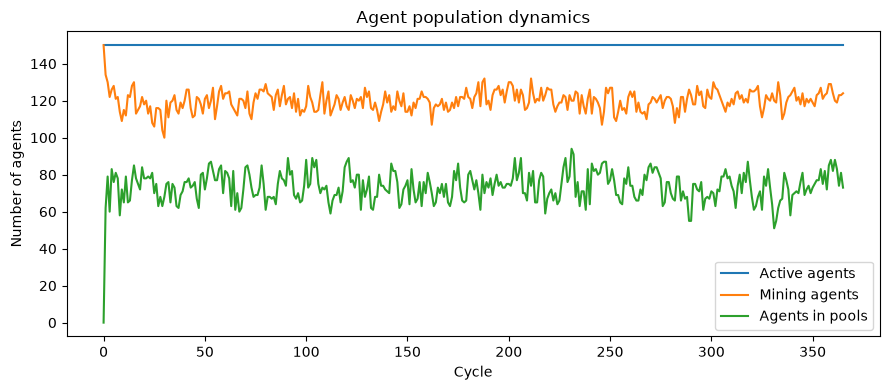

In [10]:
# Plot agent population dynamics (active, mining, and pooled miners over time)
plt.figure(figsize=(9, 4))
plt.plot(history_df["cycle"], history_df["active_agents"], label="Active agents")
plt.plot(history_df["cycle"], history_df["mining_agents"], label="Mining agents")
plt.plot(history_df["cycle"], history_df["agents_in_pools"], label="Agents in pools")
plt.xlabel("Cycle")
plt.ylabel("Number of agents")
plt.title("Agent population dynamics")
plt.legend()
plt.tight_layout()
plt.show()

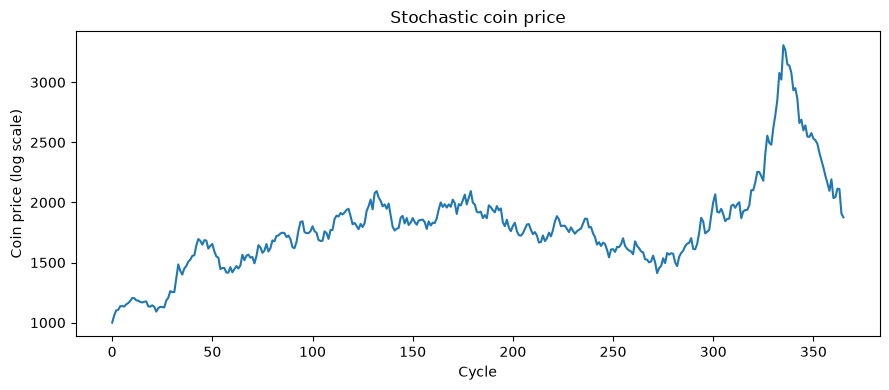

In [11]:
# Plot the stochastic cryptocurrency market price trajectory across simulation cycles
plt.figure(figsize=(9, 4))
plt.plot(history_df["cycle"], history_df["coin_price"])
#plt.yscale()
plt.xlabel("Cycle")
plt.ylabel("Coin price (log scale)")
plt.title("Stochastic coin price")
plt.tight_layout()
plt.show()




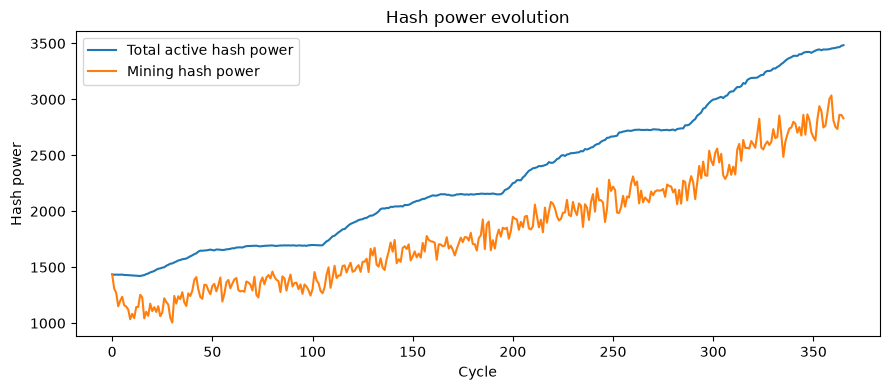

In [12]:
# Plot the evolution of total active hash power vs actively deployed mining power
plt.figure(figsize=(9, 4))
plt.plot(history_df["cycle"], history_df["total_hash_power"], label="Total active hash power")
plt.plot(history_df["cycle"], history_df["mining_hash_power"], label="Mining hash power")
plt.xlabel("Cycle")
plt.ylabel("Hash power")
plt.title("Hash power evolution")
plt.legend()
plt.tight_layout()
plt.show()

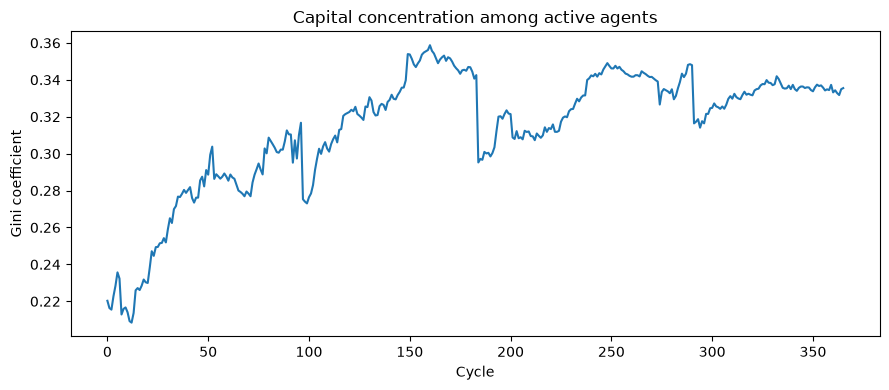

In [13]:
# Plot wealth concentration (Gini coefficient) among active agents over time
plt.figure(figsize=(9, 4))
plt.plot(history_df["cycle"], history_df["capital_gini"])
plt.xlabel("Cycle")
plt.ylabel("Gini coefficient")
plt.title("Capital concentration among active agents")
plt.tight_layout()
plt.show()

## 10. Agent outcomes

This section analyzes the end-state distribution of surviving and exited agents. We examine:
- Summary statistics (mean/median capital, hash power, risk tolerance, and profit) grouped by final agent status.
- The distribution of dominant learned strategies adopted by agents.
- The final capital distribution comparing surviving active agents against exited agents.

In [14]:
# Preview the first few rows of the final agent summary dataset
agent_df.head()

,agent_id,status,capital,initial_capital,capital_growth,initial_net_worth,net_worth,economic_profit,normalized_return,max_drawdown,...,dominant_capital_action,Q_mine,Q_invest,Q_pause,Q_repair,Q_join_pool,Q_leave_pool,Q_sell_hardware,Q_exit,Q_hold_hardware
0,1,active,2294.757525,826.166450,1468.591075,1026.509012,3223.851176,2197.342164,2.140597,0.014907,...,hold_hardware,0.017684,0.661809,0.000016,0.026122,0.012106,0.006107,0.137050,-0.579659,0.801899
1,2,active,2138.751191,925.171986,1213.579205,1252.776447,3726.684600,2473.908154,1.974740,0.014202,...,invest,0.003533,0.746179,0.000044,0.042104,0.007586,0.004505,0.206051,-0.562524,0.742823
2,3,active,3548.590358,1288.098285,2260.492072,1869.153218,4884.293738,3015.140520,1.613105,0.024252,...,hold_hardware,0.009857,0.583465,0.000005,0.014734,0.004593,0.011964,0.280074,-0.500345,0.674977
3,4,active,3012.544374,1078.003601,1934.540773,1579.615535,3948.523520,2368.907985,1.499674,0.008428,...,invest,0.007949,0.725630,0.000023,0.025996,0.005412,0.004643,0.183583,-0.582606,0.712399
4,5,active,3363.391347,1087.204343,2276.187004,2287.716117,6823.966739,4536.250621,1.982873,0.015127,...,invest,0.010453,0.800224,0.000023,0.024891,0.006149,0.006676,0.046611,-0.621568,0.743824


In [15]:
# Aggregate mean and median financial and hardware statistics by final agent status (active vs exited)
summary_by_status = agent_df.groupby("status").agg(
    agents=("agent_id", "count"),
    mean_capital=("capital", "mean"),
    median_capital=("capital", "median"),
    mean_risk=("risk_tolerance", "mean"),
    mean_hash=("hash_power", "mean"),
    mean_profit=("total_profit", "mean"),
).reset_index()

summary_by_status

,status,agents,mean_capital,median_capital,mean_risk,mean_hash,mean_profit
0,active,150,3590.972147,3393.702835,0.48778,23.227786,3790.605481


In [16]:
# Count how many agents adopted each mining action as their dominant learned strategy
learned_actions = agent_df["dominant_learned_action"].value_counts().rename_axis("dominant_action").reset_index(name="n_agents")
learned_actions

,dominant_action,n_agents
0,repair,128
1,mine,9
2,join_pool,8
3,leave_pool,5


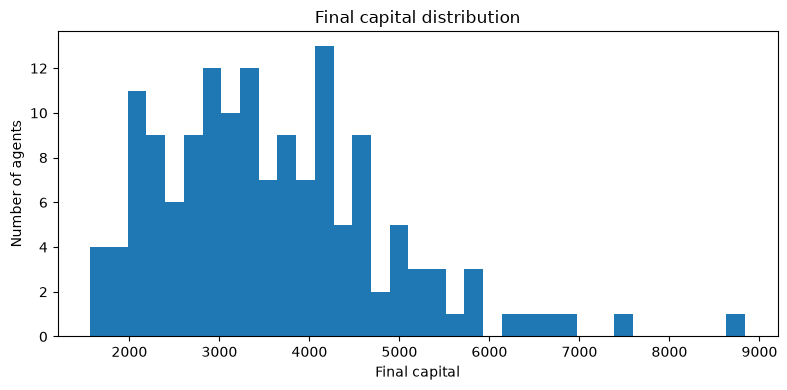

In [17]:
# Plot the histogram of final capital distribution across agents
plt.figure(figsize=(8, 4))
plt.hist(agent_df["capital"], bins=35)
plt.xlabel("Final capital")
plt.ylabel("Number of agents")
plt.title("Final capital distribution")
plt.tight_layout()
plt.show()

## 11. Simple process mining preparation

This creates a process mining event log where:

- one case = one agent;
- each event = one action or outcome;
- timestamp = simulated cycle, converted to an artificial timestamp.

The event log can be exported to CSV.

In [18]:
# Process mining preparation for Disco:
# - tie-free timestamps from (cycle, seq): cycle -> days, seq -> microseconds
# - episode-based case notion: a new episode starts at each pool join/leave,
#   so traces stay short and variant analysis remains usable
# - plain column names (for standard import mapping in process mining tools like Disco)

pm_log = event_log_df.copy()
pm_log = pm_log.sort_values(["agent_id", "cycle", "seq"]).reset_index(drop=True)

pm_log["timestamp"] = (
    pd.Timestamp("2026-01-01")
    + pd.to_timedelta(pm_log["cycle"], unit="D")
    + pd.to_timedelta(pm_log["seq"], unit="us")
)

EPISODE_BOUNDARIES = {"Join pool", "Leave pool"}

pm_log["episode"] = 0
for agent_id, group in pm_log.groupby("agent_id"):
    # The boundary event itself becomes the first event of the new episode.
    pm_log.loc[group.index, "episode"] = group["activity"].isin(EPISODE_BOUNDARIES).cumsum()

pm_log["case_id"] = (
    "Agent_" + pm_log["agent_id"].astype(str)
    + "_ep" + pm_log["episode"].astype(str).str.zfill(2)
)

pm_log[["case_id", "activity", "timestamp", "capital", "hash_power", "grid", "pool_id", "reason", "status"]].head(20)

,case_id,activity,timestamp,capital,hash_power,grid,pool_id,reason,status
0,Agent_1_ep00,Initialize,2026-01-01 00:00:00.000001,826.166450,3.612567,Grid_A_low_stable,NaN,agent_created,active
1,Agent_1_ep00,Continue mining,2026-01-02 00:00:00.000101,826.166450,3.612567,Grid_A_low_stable,NaN,daily_operation,active
2,Agent_1_ep00,Keep hardware,2026-01-02 00:00:00.000102,826.166450,3.612567,Grid_A_low_stable,NaN,capital_review,active
3,Agent_1_ep00,Continue mining,2026-01-03 00:00:00.000091,825.875671,3.612567,Grid_A_low_stable,NaN,daily_operation,active
4,Agent_1_ep00,Pause mining,2026-01-04 00:00:00.000109,825.576673,3.612567,Grid_A_low_stable,NaN,daily_operation,active
5,Agent_1_ep00,Pause mining,2026-01-05 00:00:00.000044,825.576673,3.612567,Grid_A_low_stable,NaN,daily_operation,active
6,Agent_1_ep00,Continue mining,2026-01-06 00:00:00.000083,825.576673,3.612567,Grid_A_low_stable,NaN,daily_operation,active
7,Agent_1_ep00,Imitate strategy,2026-01-06 00:00:00.000267,825.279195,3.612567,Grid_A_low_stable,NaN,social_learning,active
8,Agent_1_ep00,Pause mining,2026-01-07 00:00:00.000158,825.279195,3.612567,Grid_A_low_stable,NaN,daily_operation,active
9,Agent_1_ep00,Continue mining,2026-01-08 00:00:00.000009,825.279195,3.612567,Grid_A_low_stable,NaN,daily_operation,active


In [19]:
import os

# Create structured output subdirectories
os.makedirs("output_mas/data", exist_ok=True)
os.makedirs("output_mas/figures", exist_ok=True)

# Export simulation data for process mining and analysis
pm_log.to_csv("output_mas/data/adaptive_crypto_mining_event_log.csv", index=False)
history_df.to_csv("output_mas/data/adaptive_crypto_mining_model_history.csv", index=False)
agent_df.to_csv("output_mas/data/adaptive_crypto_mining_agent_summary.csv", index=False)

print("Exported simulation data to output_mas/data/:")
print("- adaptive_crypto_mining_event_log.csv")
print("- adaptive_crypto_mining_model_history.csv")
print("- adaptive_crypto_mining_agent_summary.csv")
# Complete decision histories are separate from visualization-filtered episodes.
decision_df.to_json("output_mas/data/adaptive_crypto_mining_decisions.jsonl", orient="records", lines=True)
print("- adaptive_crypto_mining_decisions.jsonl")


Exported simulation data to output_mas/data/:
- adaptive_crypto_mining_event_log.csv
- adaptive_crypto_mining_model_history.csv
- adaptive_crypto_mining_agent_summary.csv
- adaptive_crypto_mining_decisions.jsonl


## 12. Process Mining

This section applies process mining techniques to the generated event log using the `pm4py` library. By treating individual autonomous agents as **cases**, actions as **activities**, and simulation cycles as **timestamps**, we can discover emergent behavioral workflows, analyze bottlenecks, and compare strategies across agent cohorts.

In [20]:
# Check if Graphviz 'dot' executable is installed in PATH (required for process model rendering)
import shutil

print(shutil.which("dot"))

C:\Program Files\Graphviz\bin\dot.EXE


### 12.1 Format and clean event log for pm4py

The raw pandas DataFrame is formatted into a standard event log compatible with `pm4py`. It also cleans the data by filtering out low-value, repetitive activities like `"Continue mining"` to reduce visual noise, and prints the resulting reduction in log size.

In [21]:
import pm4py

# 1. Format the dataframe to be compatible with pm4py
pm4py_log = pm4py.format_dataframe(
    pm_log, 
    case_id='case_id', 
    activity_key='activity', 
    timestamp_key='timestamp'
)

# 2. Filter out spam/low-value activities (such as 'Continue mining') to reduce visual noise
activities_to_remove = ["Continue mining"]
clean_log = pm4py.filter_event_attribute_values(
    pm4py_log, 
    "concept:name", 
    activities_to_remove, 
    level="event", 
    retain=False
)

print(f"Original log size: {len(pm4py_log)} events")
print(f"Cleaned log size: {len(clean_log)} events")

Original log size: 100805 events
Cleaned log size: 73284 events


### 12.2 Directly-Follows Graph (DFG) discovery (Top 10 variants)

This section filters the log down to the top ten most frequent behavioral variants to establish a baseline. It then discovers and displays two Directly-Follows Graphs (DFGs): one showing the frequency of transitions between activities, and another showing the average performance time between them.

Displaying Top-K Filtered Frequency DFG...


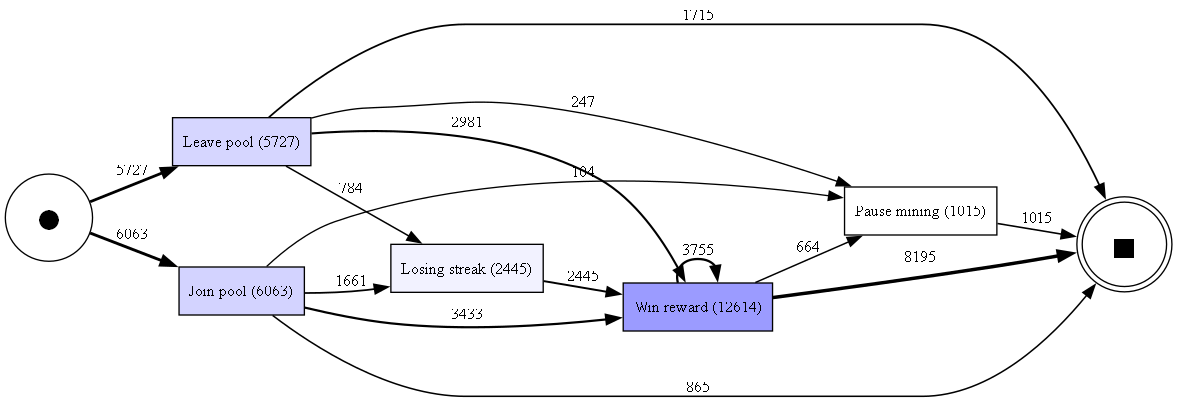

In [22]:
import pm4py

# Keep the top 10 most frequent agent behaviors
filtered_log = pm4py.filter_variants_top_k(clean_log, 20)

# 1. Discover and view Frequency DFG 
dfg, start_activities, end_activities = pm4py.discover_dfg(filtered_log)
print("Displaying Top-K Filtered Frequency DFG...")
pm4py.view_dfg(dfg, start_activities, end_activities)

### 12.3 Petri Net discovery via Inductive Miner (Frequent paths)

Discover a reference process from the five most frequent variants.
Frequency is descriptive: these paths are not necessarily profitable or rational.


Displaying 'Frequent Paths' Petri Net...


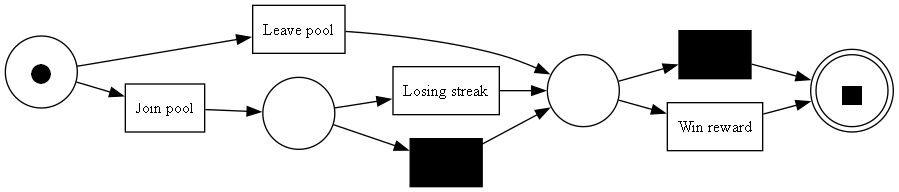

In [23]:
# 1. Filter down to the absolute most common sequences (Top 5 variants)
happy_path_log = pm4py.filter_variants_top_k(clean_log, 5) 

# 2. Discover a Petri Net using the Inductive Miner on ONLY the frequent path
net, initial_marking, final_marking = pm4py.discover_petri_net_inductive(happy_path_log)

# 3. View the structurally sound, highly readable Petri Net
print("Displaying 'Frequent Paths' Petri Net...")
pm4py.view_petri_net(net, initial_marking, final_marking)

### 12.4 BPMN Model discovery (Frequent Paths)

Using the exact same isolated "frequent path" data from the previous step, this analysis discovers and renders a Business Process Model and Notation (BPMN) diagram. This provides a more standardized, business-friendly visualization of the core process compared to a strict Petri Net.

Displaying 'Frequent Paths' BPMN Model...


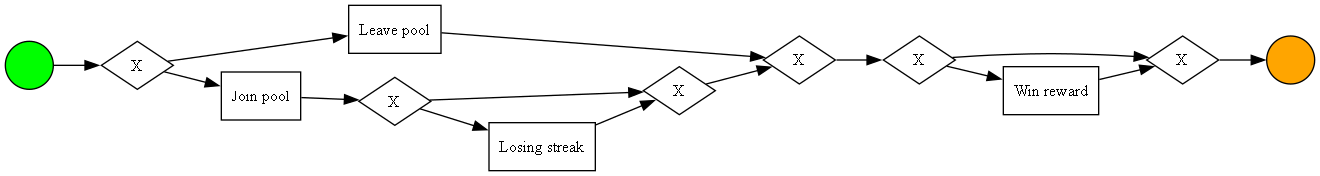

In [24]:
# Discover a BPMN model using the same isolated frequent path data
bpmn_model = pm4py.discover_bpmn_inductive(happy_path_log)

# View the BPMN model
print("Displaying 'Frequent Paths' BPMN Model...")
pm4py.view_bpmn(bpmn_model)

### 12.5 Comparative DFG analysis: Survivors vs. Losers

This section splits the log into two distinct cohorts—"Losers" and "Survivors"—based on their final outcome. By applying custom frequency thresholds to trim away rare edge cases, it renders clean, comparative DFGs to visually highlight the differing behavioral paths between failed and successful agents.

--- TOP 10 PATHS (SURVIVORS) ---
Win reward -> Win reward: 132
Win reward -> End of simulation: 94
Losing streak -> Win reward: 64
Win reward -> Pause mining: 40
Leave pool -> Win reward: 35
Join pool -> Win reward: 33
Join pool -> Losing streak: 31
Leave pool -> Losing streak: 28
Losing streak -> End of simulation: 27
Pause mining -> Win reward: 19

--- TOP 10 PATHS (LOSERS) ---


⚠️ THRESHOLD ERROR: 2 is too high for Losers. Lower it.
Displaying 'End of Simulation' DFG (Edges > 20)...


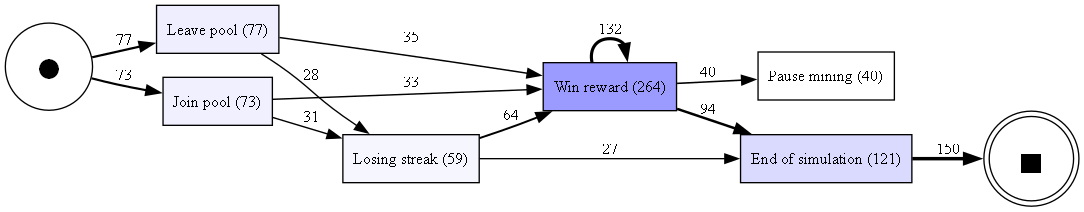

In [25]:
from collections import Counter

# 1. Split the log based on the final outcome of the case
losers_log = pm4py.filter_end_activities(clean_log, ["Exit market"])
survivors_log = pm4py.filter_end_activities(clean_log, ["End of simulation"])

# 2. Discover raw DFGs for both segments
dfg_losers, start_l, end_l = pm4py.discover_dfg(losers_log)
dfg_survivors, start_s, end_s = pm4py.discover_dfg(survivors_log)

# --- Cohort Diagnostics: Display sample sizes and activity distributions ---
print("--- TOP 10 PATHS (SURVIVORS) ---")
for path, count in Counter(dfg_survivors).most_common(10):
    print(f"{path[0]} -> {path[1]}: {count}")

print("\n--- TOP 10 PATHS (LOSERS) ---")
for path, count in Counter(dfg_losers).most_common(10):
    print(f"{path[0]} -> {path[1]}: {count}")
print("\n")

# --- THE FIX: MUCH LOWER THRESHOLDS ---
# Dropping this down so we catch the middle loops
THRESHOLD_LOSERS = 2 
THRESHOLD_SURVIVORS = 20

# Filter the "Losers" DFG
dfg_l_filtered = {k: v for k, v in dfg_losers.items() if v > THRESHOLD_LOSERS}
surviving_l_nodes = set([node for path in dfg_l_filtered.keys() for node in path])
start_l_filt = {k: v for k, v in start_l.items() if k in surviving_l_nodes}
end_l_filt = {k: v for k, v in end_l.items() if k in surviving_l_nodes}

# Filter the "Survivors" DFG
dfg_s_filtered = {k: v for k, v in dfg_survivors.items() if v > THRESHOLD_SURVIVORS}
surviving_s_nodes = set([node for path in dfg_s_filtered.keys() for node in path])
start_s_filt = {k: v for k, v in start_s.items() if k in surviving_s_nodes}
end_s_filt = {k: v for k, v in end_s.items() if k in surviving_s_nodes}
# ------------------------------------------

# 3. View the 'Exit Market' (Failure) graph
if len(dfg_l_filtered) == 0:
    print(f"⚠️ THRESHOLD ERROR: {THRESHOLD_LOSERS} is too high for Losers. Lower it.")
else:
    print(f"Displaying 'Exit Market' DFG (Edges > {THRESHOLD_LOSERS})...")
    pm4py.view_dfg(dfg_l_filtered, start_l_filt, end_l_filt)

# 4. View the 'End of Simulation' (Success) graph
if len(dfg_s_filtered) == 0:
    print(f"⚠️ THRESHOLD ERROR: {THRESHOLD_SURVIVORS} is too high for Survivors. Lower it.")
else:
    print(f"Displaying 'End of Simulation' DFG (Edges > {THRESHOLD_SURVIVORS})...")
    pm4py.view_dfg(dfg_s_filtered, start_s_filt, end_s_filt)

### 12.6 Token-based replay conformance checking

Measure resemblance to the frequent-path reference model. A deviation is not
evidence of irrationality, and higher fitness does not imply higher economic return.
The reference is discovered from this same run, so this is descriptive analysis.


In [26]:
import pm4py

# 1. Define the "Normative Model" (e.g., the top 5 most common "frequent paths")
# This is a descriptive reference, not an optimal policy.
normative_log = pm4py.filter_variants_top_k(clean_log, 5) 
net, im, fm = pm4py.discover_petri_net_inductive(normative_log)

# 2. Replay the FULL, chaotic simulation log against this clean model
# This tests resemblance to the discovered reference
fitness_dict = pm4py.fitness_token_based_replay(clean_log, net, im, fm)

print("--- CONFORMANCE CHECKING RESULTS ---")
print(f"Overall Log Fitness: {fitness_dict['log_fitness']:.2%}")

# FIX APPLIED HERE: Changed :.2% to :.2f%
print(f"Percentage of Perfectly Fit Traces: {fitness_dict['perc_fit_traces']:.2f}%")

# 3. Count deviations from the reference (not evidence of irrationality)
replayed_traces = pm4py.conformance_diagnostics_token_based_replay(clean_log, net, im, fm)

deviations = 0
for trace in replayed_traces:
    if not trace['trace_is_fit']:
        deviations += 1

print(f"Total traces containing deviations: {deviations}")

replaying log with TBR, completed traces :: 100%|██████████| 3164/3164 [00:01<00:00, 2287.49it/s]


--- CONFORMANCE CHECKING RESULTS ---
Overall Log Fitness: 78.33%
Percentage of Perfectly Fit Traces: 51.02%


replaying log with TBR, completed traces :: 100%|██████████| 3164/3164 [00:01<00:00, 2139.69it/s]

Total traces containing deviations: 9474


### 12.7 Attribute-based analytics: Grid exit rates and pooling benefits

Finally, this section converts the event log back into a pandas DataFrame to perform traditional attribute-based analytics. It dynamically locates relevant columns to aggregate market exits by their specific energy grid, and compares the average starting capital of agents who joined pools versus those who mined solo.

In [27]:
import pandas as pd

# Convert the event log to a DataFrame
df = pm4py.convert_to_dataframe(clean_log)

print("--- AVAILABLE COLUMNS IN EVENT LOG ---")
print([col for col in df.columns])
print("\n" + "="*40 + "\n")

# Automatically detect the correct column names by matching substrings
grid_col = next((c for c in df.columns if 'grid' in c.lower()), None)
capital_col = next((c for c in df.columns if 'capital' in c.lower()), None)

# 1. Market Exits by Energy Grid
if grid_col:
    exit_events = df[df['concept:name'] == 'Exit market']
    if not exit_events.empty:
        grid_exits = exit_events.groupby(grid_col).size()
        print("--- MARKET EXITS BY ENERGY GRID ---")
        print(grid_exits)
    else:
        print("--- MARKET EXITS BY ENERGY GRID ---")
        print("No 'Exit market' events found in this subset.")
else:
    print("Could not find an energy grid column. Check the printed list above.")

print("\n" + "="*40 + "\n")

# 2. Capital vs Pool Dynamics
if capital_col:
    pool_events = df[df['concept:name'] == 'Join pool']
    if not pool_events.empty:
        # Get unique case IDs for agents who joined pools
        pool_cases = pool_events['case:concept:name'].unique()
        
        avg_pool_capital = df[df['case:concept:name'].isin(pool_cases)][capital_col].mean()
        avg_solo_capital = df[~df['case:concept:name'].isin(pool_cases)][capital_col].mean()
        
        print("--- POOL DYNAMICS BY INITIAL CAPITAL ---")
        print(f"Avg capital of agents who joined pools: {avg_pool_capital:.2f}")
        print(f"Avg capital of strictly solo agents: {avg_solo_capital:.2f}")
    else:
        print("--- POOL DYNAMICS ---")
        print("No 'Join pool' events found in the log.")
else:
    print("Could not find a capital column. Check the printed list above.")

--- AVAILABLE COLUMNS IN EVENT LOG ---
['case_id', 'agent_id', 'cycle', 'seq', 'activity', 'reason', 'capital', 'hash_power', 'risk_tolerance', 'hardware_efficiency', 'grid', 'energy_price', 'coin_price', 'pool_id', 'status', 'paused', 'last_action', 'hash_lost', 'new_pool', 'amount', 'hash_repaired', 'hash_ordered', 'delivery_day', 'estimated_payback_days', 'reward', 'cost', 'profit', 'pool_or_solo_blocks', 'mentor_id', 'old_pool', 'streak_length', 'streak_cost', 'hash_sold', 'hash_added', 'timestamp', 'episode', 'case:concept:name', 'concept:name', 'time:timestamp', '@@index', '@@case_index']


--- MARKET EXITS BY ENERGY GRID ---
No 'Exit market' events found in this subset.


--- POOL DYNAMICS BY INITIAL CAPITAL ---
Avg capital of agents who joined pools: 2253.77
Avg capital of strictly solo agents: 2267.13


### 12.8 Top-performing agents analysis (Wealth quantiles)

This section filters the event log by agent case IDs to isolate the highest-wealth agents (top 1% and top 10% quantiles) and analyze their specific activity profiles and success factors.

Original DFG edges: 57 → Filtered: 32

Displaying Tactics of the Top 10% Best Performing Agents (frequency-filtered DFG)...


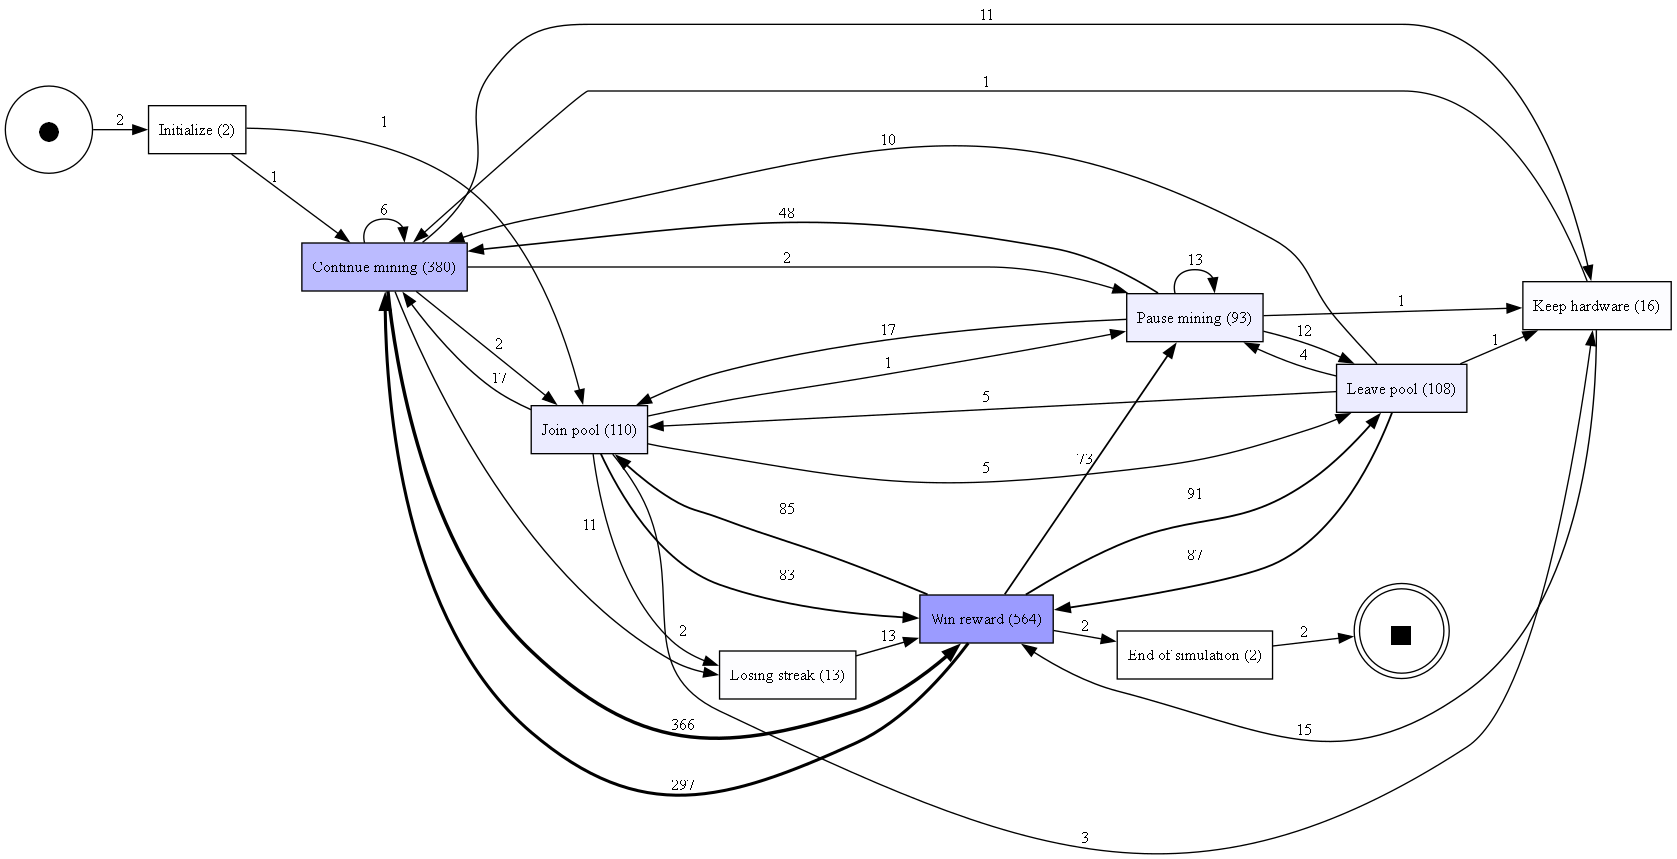

In [28]:
import pandas as pd
import pm4py
QUANTILE = 0.99
FILTERTRESHOLD = 0.4
# 1. Load the data
df = pd.read_csv("output_mas/data/adaptive_crypto_mining_event_log.csv")

# ---------------------------------------------------------
# STEP 1: Identify the "Best" Agents (top 10% by final capital)
# ---------------------------------------------------------
final_states = df.groupby('agent_id').last()
wealth_threshold = final_states['capital'].quantile(QUANTILE)
best_agent_ids = final_states[final_states['capital'] >= wealth_threshold].index

# ---------------------------------------------------------
# STEP 2: Filter the Event Log
# ---------------------------------------------------------
best_agents_df = df[df['agent_id'].isin(best_agent_ids)].copy()

# ---------------------------------------------------------
# STEP 3: Format for PM4Py
# ---------------------------------------------------------
best_agents_log = pm4py.format_dataframe(
    best_agents_df,
    case_id='agent_id',
    activity_key='activity',
    timestamp_key='timestamp'
)

# ---------------------------------------------------------
# STEP 4: Generate a CLEAN DFG (frequency-filtered)
# ---------------------------------------------------------
dfg, start_activities, end_activities = pm4py.discover_dfg(best_agents_log)

from pm4py.algo.filtering.dfg import dfg_filtering
from pm4py.statistics.attributes.log import get as attr_get

activities_count = attr_get.get_attribute_values(best_agents_log, 'activity')

filtered_dfg, filtered_sa, filtered_ea, filtered_ac = dfg_filtering.filter_dfg_on_activities_percentage(
    dfg, start_activities, end_activities, activities_count, FILTERTRESHOLD
)

print(f"Original DFG edges: {len(dfg)} → Filtered: {len(filtered_dfg)}")
print("\nDisplaying Tactics of the Top 10% Best Performing Agents (frequency-filtered DFG)...")
pm4py.view_dfg(filtered_dfg, filtered_sa, filtered_ea)

### 12.9 Behavioral comparison: Top 10% vs. Bottom 10% performers

Discovers and compares directly-follows graphs (DFGs) for the wealthiest 10% of agents against the poorest 10%, highlighting differences in strategic decision-making and activity sequencing.

Loading data...
Formatting logs...
Discovering DFGs...
Saving visualizations...

--- Statistical Comparison ---
Top 10% Agents: 15 agents, Mean Final Capital: $6151.00, Total Events: 10325
Bottom 10% Agents: 15 agents, Mean Final Capital: $1938.26, Total Events: 9591
Saved comparison figure to output_mas/figures/cell1_best_vs_worst.png
Exported raw data to output_mas/figures/cell1_*_data.csv


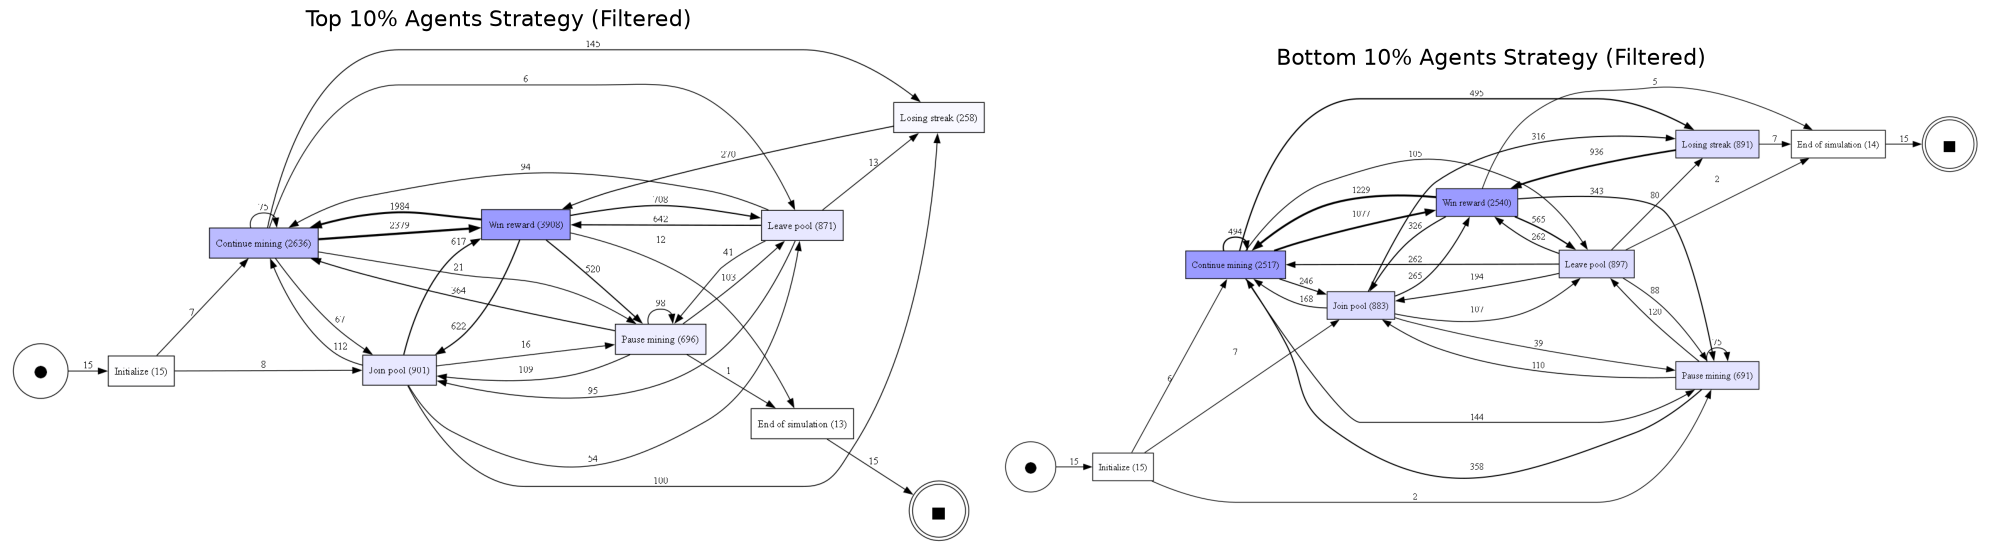

In [29]:
import pandas as pd
import pm4py
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pm4py.algo.filtering.dfg import dfg_filtering
from pm4py.statistics.attributes.log import get as attr_get
import os

# 1. Load data
print("Loading data...")
df = pd.read_csv("output_mas/data/adaptive_crypto_mining_event_log.csv")

# 2. Get top 10% and bottom 10% agents by final capital
final_states = df.groupby('agent_id').last()
top_thresh = final_states['capital'].quantile(0.90)
bottom_thresh = final_states['capital'].quantile(0.10)

top_ids = final_states[final_states['capital'] >= top_thresh].index
bottom_ids = final_states[final_states['capital'] <= bottom_thresh].index

top_df = df[df['agent_id'].isin(top_ids)].copy()
bottom_df = df[df['agent_id'].isin(bottom_ids)].copy()

# 3. Format as PM4Py logs
print("Formatting logs...")
top_log = pm4py.format_dataframe(top_df, case_id='agent_id', activity_key='activity', timestamp_key='timestamp')
bottom_log = pm4py.format_dataframe(bottom_df, case_id='agent_id', activity_key='activity', timestamp_key='timestamp')

# 4. Discover and filter DFGs
print("Discovering DFGs...")
top_dfg, top_sa, top_ea = pm4py.discover_dfg(top_log)
bottom_dfg, bottom_sa, bottom_ea = pm4py.discover_dfg(bottom_log)

top_ac = attr_get.get_attribute_values(top_log, 'activity')
bottom_ac = attr_get.get_attribute_values(bottom_log, 'activity')

filt_top_dfg, filt_top_sa, filt_top_ea, _ = dfg_filtering.filter_dfg_on_activities_percentage(top_dfg, top_sa, top_ea, top_ac, 0.3)
filt_bot_dfg, filt_bot_sa, filt_bot_ea, _ = dfg_filtering.filter_dfg_on_activities_percentage(bottom_dfg, bottom_sa, bottom_ea, bottom_ac, 0.3)

# 5. Save visualizations
print("Saving visualizations...")
pm4py.save_vis_dfg(filt_top_dfg, filt_top_sa, filt_top_ea, 'output_mas/figures/top_dfg.png')
pm4py.save_vis_dfg(filt_bot_dfg, filt_bot_sa, filt_bot_ea, 'output_mas/figures/bottom_dfg.png')

# 6. Display comparison
print("\n--- Statistical Comparison ---")
print(f"Top 10% Agents: {len(top_ids)} agents, Mean Final Capital: ${final_states.loc[top_ids, 'capital'].mean():.2f}, Total Events: {len(top_df)}")
print(f"Bottom 10% Agents: {len(bottom_ids)} agents, Mean Final Capital: ${final_states.loc[bottom_ids, 'capital'].mean():.2f}, Total Events: {len(bottom_df)}")

# Create plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

if os.path.exists('output_mas/figures/top_dfg.png'):
    img1 = mpimg.imread('output_mas/figures/top_dfg.png')
    ax1.imshow(img1)
ax1.set_title("Top 10% Agents Strategy (Filtered)", fontsize=16)
ax1.axis('off')

if os.path.exists('output_mas/figures/bottom_dfg.png'):
    img2 = mpimg.imread('output_mas/figures/bottom_dfg.png')
    ax2.imshow(img2)
ax2.set_title("Bottom 10% Agents Strategy (Filtered)", fontsize=16)
ax2.axis('off')

plt.tight_layout()
plt.savefig('output_mas/figures/cell1_best_vs_worst.png')
print("Saved comparison figure to output_mas/figures/cell1_best_vs_worst.png")

# ── Export raw data for LaTeX/TikZ ──
top_summary = pd.DataFrame({'agent_id': top_ids, 'final_capital': final_states.loc[top_ids, 'capital'].values, 'tier': 'top_10pct'})
bot_summary = pd.DataFrame({'agent_id': bottom_ids, 'final_capital': final_states.loc[bottom_ids, 'capital'].values, 'tier': 'bottom_10pct'})
pd.concat([top_summary, bot_summary]).to_csv('output_mas/figures/cell1_best_vs_worst_data.csv', index=False)
# Export DFG edge tables
pd.DataFrame([(k, v) for k, v in filt_top_dfg.items()], columns=['edge', 'frequency']).to_csv('output_mas/figures/cell1_top_dfg_edges.csv', index=False)
pd.DataFrame([(k, v) for k, v in filt_bot_dfg.items()], columns=['edge', 'frequency']).to_csv('output_mas/figures/cell1_bot_dfg_edges.csv', index=False)
print('Exported raw data to output_mas/figures/cell1_*_data.csv')


### 12.10 Exit market analysis: Tracing agent capitulation

Examines the behavioral traces of agents who exited the market to understand the sequence of events leading to bankruptcy or voluntary capitulation.

In [30]:
import pandas as pd
import pm4py
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pm4py.algo.filtering.dfg import dfg_filtering
from pm4py.statistics.attributes.log import get as attr_get
import os

print("Loading data...")
df = pd.read_csv("output_mas/data/adaptive_crypto_mining_event_log.csv")

# 1. Find agents who exited
exit_agents = df[df['activity'] == 'Exit market']['agent_id'].unique()
print(f"Found {len(exit_agents)} agents who exited.")

if len(exit_agents) == 0:
    print("\n--- Survival Analysis ---")
    print("100% Survival Rate: No agents exited or capitulated during this run.")
    print("All agents maintained sufficient capital or solvency above the bankruptcy threshold.")
    print("Skipping death trace DFG (requires at least 1 market exit).")
else:
    # 2. Extract the last 5 activities before 'Exit market'
    death_traces = []
    for aid in exit_agents:
        agent_df = df[df['agent_id'] == aid]
        agent_df_no_exit = agent_df[agent_df['activity'] != 'Exit market']
        death_traces.append(agent_df_no_exit.tail(5))

    death_df = pd.concat(death_traces)

    # 3. Discover AND FILTER death trace DFG
    death_log = pm4py.format_dataframe(death_df, case_id='agent_id', activity_key='activity', timestamp_key='timestamp')
    dfg, sa, ea = pm4py.discover_dfg(death_log)

    # Filter out noise
    activities_count = attr_get.get_attribute_values(death_log, 'activity')
    filt_dfg, filt_sa, filt_ea, _ = dfg_filtering.filter_dfg_on_activities_percentage(dfg, sa, ea, activities_count, 0.5)

    # 4. Print stats
    exit_events = df[df['activity'] == 'Exit market']
    print("\n--- Survival Analysis ---")
    print(f"Total Agents Dead: {len(exit_agents)}")
    print(f"Mean capital at death: ${exit_events['capital'].mean():.2f}")
    print(f"Mean cycle of death: {exit_events['cycle'].mean():.1f}")
    print("\nExit reasons:")
    print(exit_events['reason'].value_counts())

    print("\nMost common activities right before exit:")
    last_activities = death_df.groupby('agent_id').last()['activity']
    print(last_activities.value_counts().head(5))

    # 5. Display DFG
    pm4py.save_vis_dfg(filt_dfg, filt_sa, filt_ea, 'output_mas/figures/survival_dfg.png')
    if os.path.exists('output_mas/figures/survival_dfg.png'):
        plt.figure(figsize=(15, 10))
        plt.imshow(mpimg.imread('output_mas/figures/survival_dfg.png'))
        plt.title("The Death Spiral: Last 5 Activities Before Death (Filtered)", fontsize=16)
        plt.axis('off')
        plt.show()


Loading data...
Found 0 agents who exited.

--- Survival Analysis ---
100% Survival Rate: No agents exited or capitulated during this run.
All agents maintained sufficient capital or solvency above the bankruptcy threshold.
Skipping death trace DFG (requires at least 1 market exit).


### 12.11 Tiered wealth distribution and activity profiles

Categorizes agents into wealth quartiles and analyzes how activity frequencies (such as pooling, pausing, and investing) vary across performance tiers.

Loading data...
Processing trajectories...
Plotting...
Saved figure to output_mas/figures/cell3_capital.png
Exported raw data to output_mas/figures/cell3_capital_data.csv


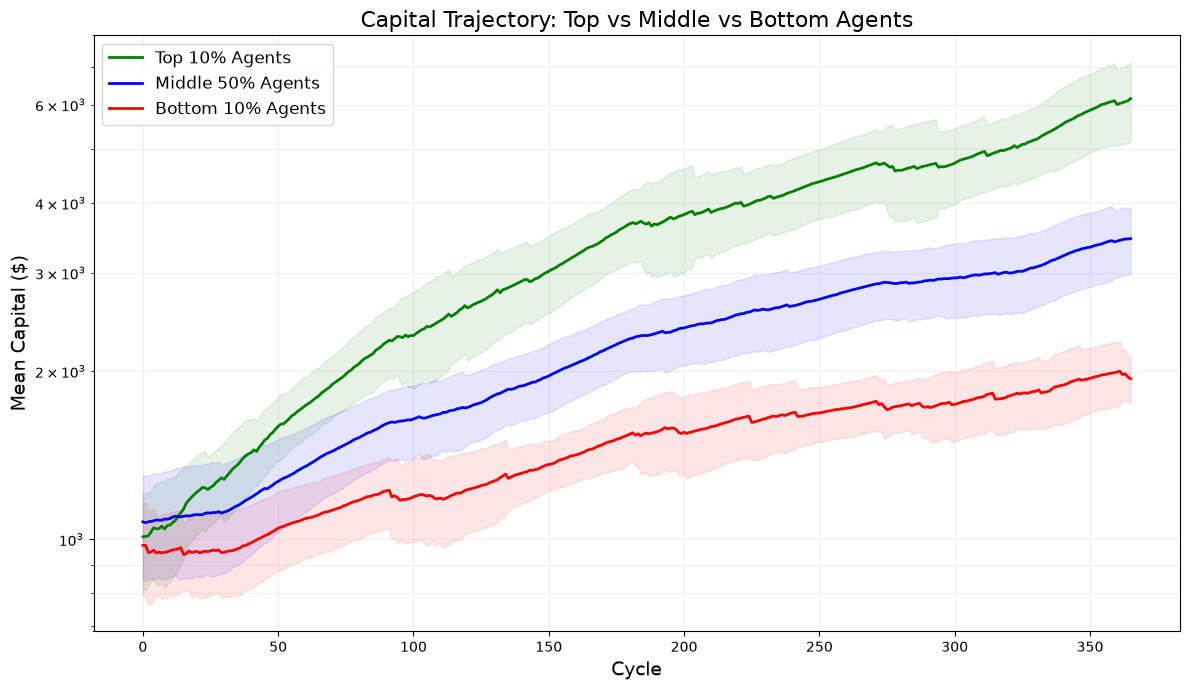

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

print("Loading data...")
df = pd.read_csv("output_mas/data/adaptive_crypto_mining_event_log.csv")

# 1. Group agents into tiers
final_states = df.groupby('agent_id').last()

top_thresh = final_states['capital'].quantile(0.90)
bottom_thresh = final_states['capital'].quantile(0.10)
mid_upper = final_states['capital'].quantile(0.75)
mid_lower = final_states['capital'].quantile(0.25)

top_ids = final_states[final_states['capital'] >= top_thresh].index
bottom_ids = final_states[final_states['capital'] <= bottom_thresh].index
mid_ids = final_states[(final_states['capital'] >= mid_lower) & (final_states['capital'] <= mid_upper)].index

# 2. Get capital per cycle per agent
print("Processing trajectories...")
# To get the trajectory, we want the LAST event in each cycle for each agent
cycle_states = df.groupby(['cycle', 'agent_id']).last().reset_index()

# 3. Compute mean and std per tier per cycle
top_traj = cycle_states[cycle_states['agent_id'].isin(top_ids)].groupby('cycle')['capital'].agg(['mean', 'std']).fillna(0)
mid_traj = cycle_states[cycle_states['agent_id'].isin(mid_ids)].groupby('cycle')['capital'].agg(['mean', 'std']).fillna(0)
bot_traj = cycle_states[cycle_states['agent_id'].isin(bottom_ids)].groupby('cycle')['capital'].agg(['mean', 'std']).fillna(0)

# 4. Plot
print("Plotting...")
plt.style.use('default') # Avoid seaborn dependency error if not installed
plt.figure(figsize=(12, 7))

# Top 10%
plt.plot(top_traj.index, top_traj['mean'], color='green', linewidth=2, label='Top 10% Agents')
plt.fill_between(top_traj.index, top_traj['mean'] - top_traj['std'], top_traj['mean'] + top_traj['std'], color='green', alpha=0.1)

# Middle 50%
plt.plot(mid_traj.index, mid_traj['mean'], color='blue', linewidth=2, label='Middle 50% Agents')
plt.fill_between(mid_traj.index, mid_traj['mean'] - mid_traj['std'], mid_traj['mean'] + mid_traj['std'], color='blue', alpha=0.1)

# Bottom 10%
plt.plot(bot_traj.index, bot_traj['mean'], color='red', linewidth=2, label='Bottom 10% Agents')
plt.fill_between(bot_traj.index, bot_traj['mean'] - bot_traj['std'], bot_traj['mean'] + bot_traj['std'], color='red', alpha=0.1)

plt.title('Capital Trajectory: Top vs Middle vs Bottom Agents', fontsize=16)
plt.xlabel('Cycle', fontsize=14)
plt.ylabel('Mean Capital ($)', fontsize=14)
plt.yscale('log') # Log scale because of exponential growth
plt.legend(fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.tight_layout()

plt.savefig('output_mas/figures/cell3_capital.png')
print("Saved figure to output_mas/figures/cell3_capital.png")

# ── Export raw data for LaTeX/TikZ ──
traj_export = pd.DataFrame({
    'cycle': top_traj.index,
    'top_mean': top_traj['mean'].values, 'top_std': top_traj['std'].values,
    'mid_mean': mid_traj['mean'].values[:len(top_traj)], 'mid_std': mid_traj['std'].values[:len(top_traj)],
    'bot_mean': bot_traj['mean'].values[:len(top_traj)], 'bot_std': bot_traj['std'].values[:len(top_traj)],
})
traj_export.to_csv('output_mas/figures/cell3_capital_data.csv', index=False)
print('Exported raw data to output_mas/figures/cell3_capital_data.csv')


### 12.12 Social learning and mentor imitation network

Investigates the social learning mechanism by tracking which successful mentors were most frequently imitated by peers, and how imitation correlated with final wealth accumulation.

Loading data...

--- Social Network Analysis ---
Top 10 Most Imitated Agents:
   Agent ID  Times Imitated Final Capital ($)
0        84             535           8840.07
1       102             182           6704.02
2        10             166           5910.82
3       122             133           6807.73
4        52              93           5825.51
5        57              90           3887.15
6       150              75           5901.89
7        48              70           6356.94
8        53              50           5333.66
9       140              50           3303.48
Saved figure to output_mas/figures/cell4_social.png
Exported raw data to output_mas/figures/cell4_social_data.csv


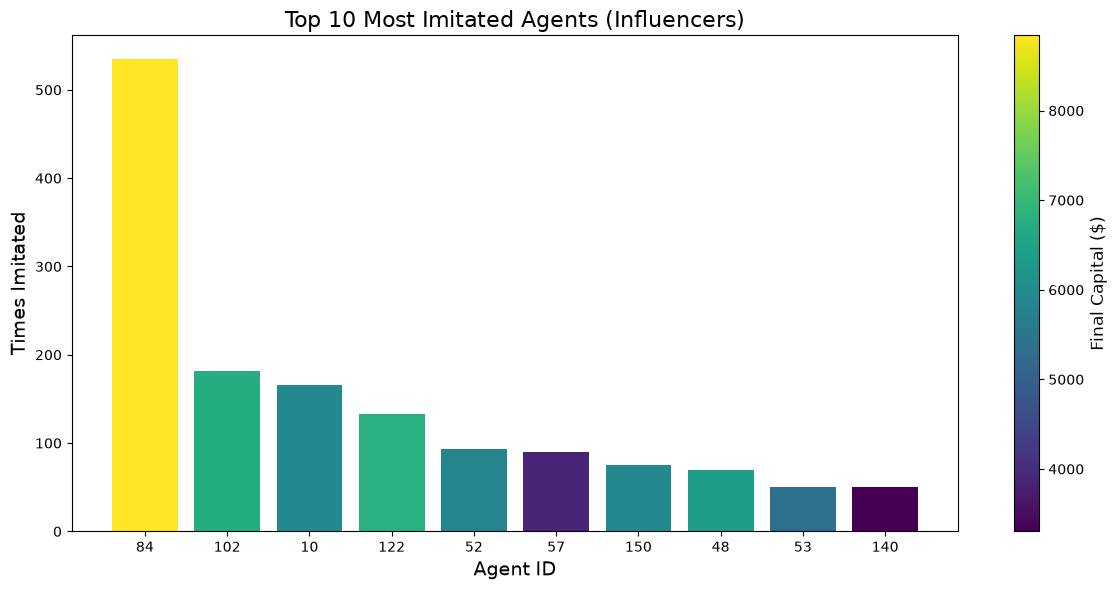

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

print("Loading data...")
df = pd.read_csv("output_mas/data/adaptive_crypto_mining_event_log.csv")

# 1. Filter to Imitate strategy
imitations = df[df['activity'] == 'Imitate strategy'].dropna(subset=['mentor_id'])

# 2. Count how many times each mentor was imitated
mentor_counts = imitations['mentor_id'].value_counts()

# 3. Get final capital for each agent
final_states = df.groupby('agent_id').last()

# 4. Find the top 10 most-imitated agents
top_mentors = mentor_counts.head(10)

top_mentor_ids = top_mentors.index.astype(int)
top_mentor_counts = top_mentors.values
top_mentor_capitals = final_states.loc[top_mentor_ids, 'capital'].values

print("\n--- Social Network Analysis ---")
print("Top 10 Most Imitated Agents:")
print(pd.DataFrame({
    'Agent ID': top_mentor_ids,
    'Times Imitated': top_mentor_counts,
    'Final Capital ($)': [f"{c:.2f}" for c in top_mentor_capitals]
}))

# 5. Visualization
plt.style.use('default')
plt.figure(figsize=(12, 6))

# Create a colormap based on capital
norm = plt.Normalize(top_mentor_capitals.min(), top_mentor_capitals.max())
colors = cm.viridis(norm(top_mentor_capitals))

bars = plt.bar([str(i) for i in top_mentor_ids], top_mentor_counts, color=colors)

# Add colorbar
sm = plt.cm.ScalarMappable(cmap=cm.viridis, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label('Final Capital ($)', fontsize=12)

plt.title('Top 10 Most Imitated Agents (Influencers)', fontsize=16)
plt.xlabel('Agent ID', fontsize=14)
plt.ylabel('Times Imitated', fontsize=14)
plt.tight_layout()

plt.savefig('output_mas/figures/cell4_social.png')
print("Saved figure to output_mas/figures/cell4_social.png")

# ── Export raw data for LaTeX/TikZ ──
mentor_export = pd.DataFrame({
    'agent_id': top_mentor_ids,
    'times_imitated': top_mentor_counts,
    'final_capital': top_mentor_capitals,
})
mentor_export.to_csv('output_mas/figures/cell4_social_data.csv', index=False)
print('Exported raw data to output_mas/figures/cell4_social_data.csv')


### 12.13 Longitudinal activity patterns of top-performing agents

Analyzes how the action choices of the top 10% wealthiest agents evolved across simulation cycles over time.

Loading data...

--- Grid Strategy Analysis (Top 10% Agents) ---
Saved figure to output_mas/figures/cell5_grid.png
Exported raw data to output_mas/figures/cell5_grid_data.csv


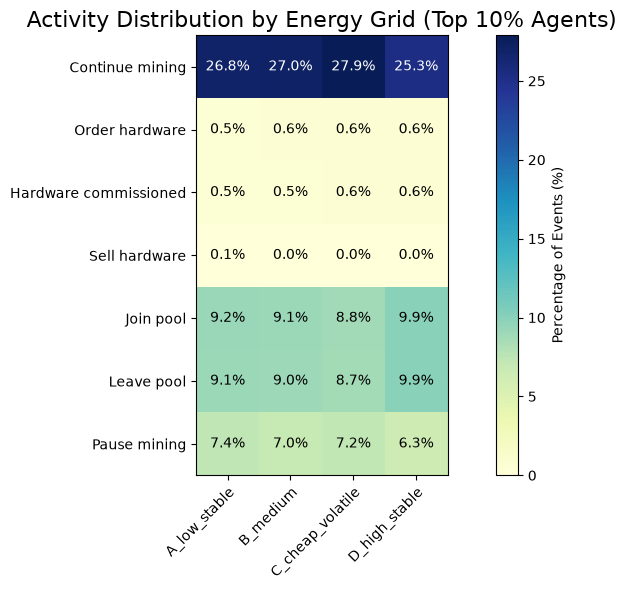

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("Loading data...")
df = pd.read_csv("output_mas/data/adaptive_crypto_mining_event_log.csv")

# 1. Get top 10% agents
final_states = df.groupby('agent_id').last()
top_thresh = final_states['capital'].quantile(0.90)
top_ids = final_states[final_states['capital'] >= top_thresh].index

top_df = df[df['agent_id'].isin(top_ids)]

# 2. Main activities to focus on
main_activities = [
    'Continue mining', 'Order hardware', 'Hardware commissioned', 'Sell hardware', 
    'Join pool', 'Leave pool', 'Pause mining'
]

# 3. Calculate percentage distribution per grid
grid_types = sorted(top_df['grid'].unique())
heatmap_data = []

print("\n--- Grid Strategy Analysis (Top 10% Agents) ---")
for act in main_activities:
    row = []
    for grid in grid_types:
        grid_df = top_df[top_df['grid'] == grid]
        total = len(grid_df)
        if total > 0:
            count = len(grid_df[grid_df['activity'] == act])
            pct = (count / total) * 100
        else:
            pct = 0
        row.append(pct)
    heatmap_data.append(row)

heatmap_data = np.array(heatmap_data)

# 4. Visualization
plt.style.use('default')
fig, ax = plt.subplots(figsize=(10, 6))

im = ax.imshow(heatmap_data, cmap='YlGnBu')

# We want to show all ticks...
ax.set_xticks(np.arange(len(grid_types)))
ax.set_yticks(np.arange(len(main_activities)))
# ... and label them with the respective list entries
ax.set_xticklabels([g.replace('Grid_', '') for g in grid_types])
ax.set_yticklabels(main_activities)

# Rotate the tick labels and set their alignment.
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Loop over data dimensions and create text annotations.
for i in range(len(main_activities)):
    for j in range(len(grid_types)):
        text = ax.text(j, i, f"{heatmap_data[i, j]:.1f}%",
                       ha="center", va="center", color="black" if heatmap_data[i, j] < 20 else "white")

ax.set_title("Activity Distribution by Energy Grid (Top 10% Agents)", fontsize=16)
fig.tight_layout()

plt.colorbar(im, label='Percentage of Events (%)')
plt.savefig('output_mas/figures/cell5_grid.png')
print("Saved figure to output_mas/figures/cell5_grid.png")

# ── Export raw data for LaTeX/TikZ ──
heatmap_df = pd.DataFrame(heatmap_data, index=main_activities,
                          columns=[g.replace('Grid_', '') for g in grid_types])
heatmap_df.to_csv('output_mas/figures/cell5_grid_data.csv')
print('Exported raw data to output_mas/figures/cell5_grid_data.csv')


### 12.14 Agent trait correlations and financial outcomes

Visualizes relationships between initial agent traits (such as risk tolerance, hardware efficiency, and initial capital) and their final financial performance.

Loading data...
Computing next activities...

--- Decision Point Analysis ---
Top next activities after 'Continue mining':
next_activity
Win reward         16574
Losing streak       3815
Continue mining     2926
Join pool           1542
Pause mining         760
Name: count, dtype: int64

Mean Market Conditions at Decision Point:
                  coin_price  energy_price      capital
next_activity                                          
Continue mining  1818.183413      0.254644  2024.299811
Join pool        1802.209534      0.243888  2073.876366
Losing streak    1800.947995      0.250194  2066.732521
Pause mining     1804.778255      0.259248  1981.002045
Win reward       1799.315674      0.238994  2412.948085
Saved figure to output_mas/figures/cell6_decision.png
Exported raw data to output_mas/figures/cell6_decision_*.csv


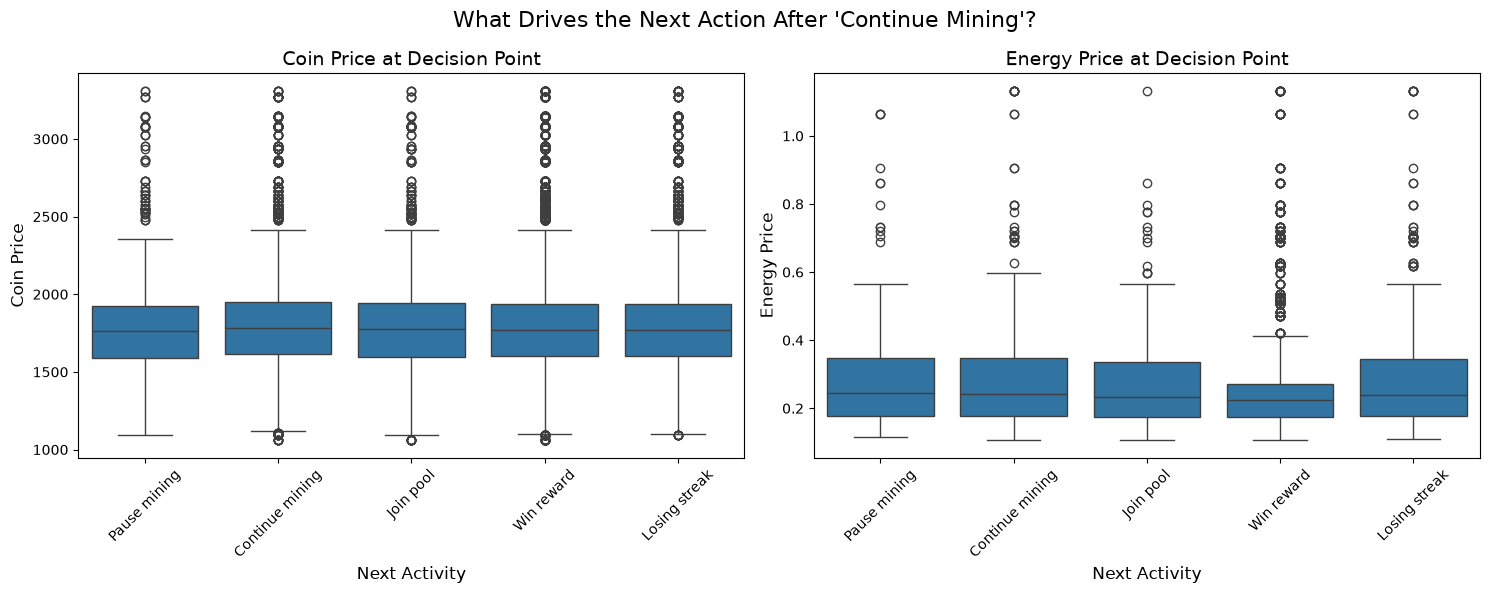

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
try:
    import seaborn as sns
    HAS_SNS = True
except ModuleNotFoundError:
    HAS_SNS = False
    
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Loading data...")
df = pd.read_csv("output_mas/data/adaptive_crypto_mining_event_log.csv")

# 1. Get next activity for each row
print("Computing next activities...")
df['next_activity'] = df.groupby('agent_id')['activity'].shift(-1)

# 2. Filter to rows where current activity is 'Continue mining'
mining_df = df[df['activity'] == 'Continue mining'].dropna(subset=['next_activity'])

# 3. Get top 5 next activities
top_next = mining_df['next_activity'].value_counts().head(5).index
decision_df = mining_df[mining_df['next_activity'].isin(top_next)]

print("\n--- Decision Point Analysis ---")
print("Top next activities after 'Continue mining':")
print(mining_df['next_activity'].value_counts().head(5))

# 4. Summary table
print("\nMean Market Conditions at Decision Point:")
summary = decision_df.groupby('next_activity')[['coin_price', 'energy_price', 'capital']].mean()
print(summary)

# 5. Visualization
plt.style.use('default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

try:
    sns.boxplot(data=decision_df, x='next_activity', y='coin_price', ax=ax1)
    sns.boxplot(data=decision_df, x='next_activity', y='energy_price', ax=ax2)
except Exception:
    # Fallback if seaborn fails
    decision_df.boxplot(column='coin_price', by='next_activity', ax=ax1, grid=False)
    decision_df.boxplot(column='energy_price', by='next_activity', ax=ax2, grid=False)

ax1.set_title('Coin Price at Decision Point', fontsize=14)
ax1.set_xlabel('Next Activity', fontsize=12)
ax1.set_ylabel('Coin Price', fontsize=12)
ax1.tick_params(axis='x', rotation=45)

ax2.set_title('Energy Price at Decision Point', fontsize=14)
ax2.set_xlabel('Next Activity', fontsize=12)
ax2.set_ylabel('Energy Price', fontsize=12)
ax2.tick_params(axis='x', rotation=45)

fig.suptitle("What Drives the Next Action After 'Continue Mining'?", fontsize=16)
plt.tight_layout()

plt.savefig('output_mas/figures/cell6_decision.png')
print("Saved figure to output_mas/figures/cell6_decision.png")

# ── Export raw data for LaTeX/TikZ ──
summary.to_csv('output_mas/figures/cell6_decision_summary.csv')
decision_df[['next_activity', 'coin_price', 'energy_price', 'capital']].to_csv(
    'output_mas/figures/cell6_decision_boxplot_data.csv', index=False)
print('Exported raw data to output_mas/figures/cell6_decision_*.csv')


### 12.15 Energy grid paradox analysis

Evaluates the distribution of top-performing agents across different local energy grids to investigate whether low energy costs guarantee mining success, or if volatility and shocks outweigh base price advantages.

Loading data...


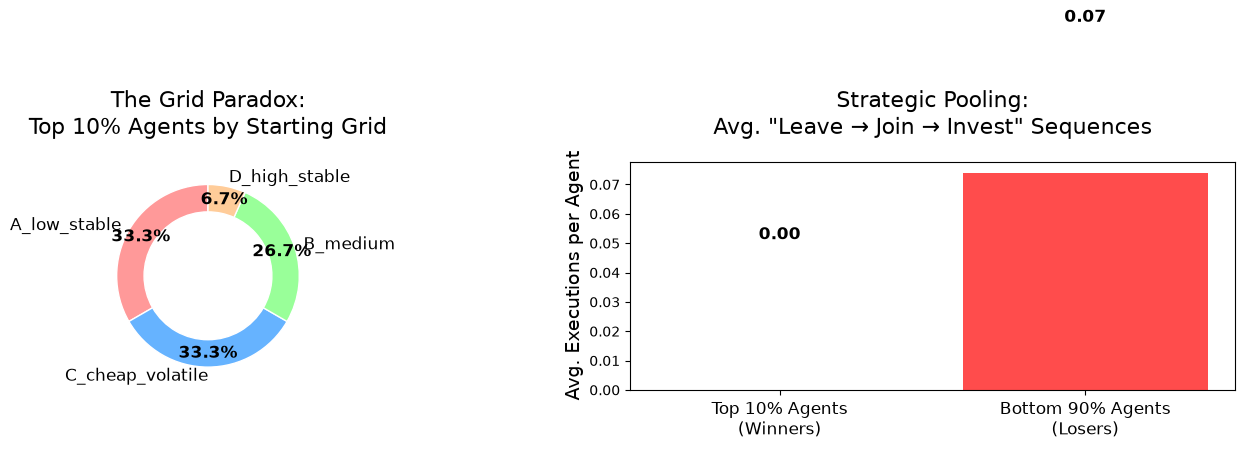

Exported raw data to output_mas/figures/cell7_grid_paradox_data.csv


In [35]:
import pandas as pd
import matplotlib.pyplot as plt

print("Loading data...")
df = pd.read_csv("output_mas/data/adaptive_crypto_mining_event_log.csv")

# 1. Grid Paradox Data
final_states = df.groupby('agent_id').last()
top_10 = final_states[final_states['capital'] >= final_states['capital'].quantile(0.90)]
grid_counts = top_10['grid'].value_counts()

# Clean up grid names for display
grid_labels = [g.replace('Grid_', '') for g in grid_counts.index]
grid_sizes = grid_counts.values
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']

# 2. Strategic Pooling Data (Leave -> Join -> Invest sequence)
df['next_act'] = df.groupby('agent_id')['activity'].shift(-1)
df['next_next_act'] = df.groupby('agent_id')['activity'].shift(-2)

strat_hop = df[(df['activity'] == 'Leave pool') & 
               (df['next_act'] == 'Join pool') & 
               (df['next_next_act'] == 'Order hardware')]

top_10_ids = top_10.index
top_strat_avg = len(strat_hop[strat_hop['agent_id'].isin(top_10_ids)]) / len(top_10_ids)
bot_strat_avg = len(strat_hop[~strat_hop['agent_id'].isin(top_10_ids)]) / (len(final_states) - len(top_10_ids))

# 3. Visualization
plt.style.use('default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left: Pie Chart (The Grid Paradox)
wedges, texts, autotexts = ax1.pie(grid_sizes, colors=colors, labels=grid_labels, autopct='%1.1f%%', 
                                   startangle=90, pctdistance=0.85, 
                                   wedgeprops=dict(width=0.3, edgecolor='w'))
ax1.set_title('The Grid Paradox:\nTop 10% Agents by Starting Grid', fontsize=16, pad=20)
plt.setp(autotexts, size=12, weight="bold")
plt.setp(texts, size=12)

# Right: Bar Chart (Strategic Pooling)
bars = ax2.bar(['Top 10% Agents\n(Winners)', 'Bottom 90% Agents\n(Losers)'], 
               [top_strat_avg, bot_strat_avg], 
               color=['green', 'red'], alpha=0.7)

ax2.set_title('Strategic Pooling:\nAvg. "Leave → Join → Invest" Sequences', fontsize=16, pad=20)
ax2.set_ylabel('Avg. Executions per Agent', fontsize=14)
ax2.tick_params(axis='x', labelsize=12)

# Add values on bars
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.2f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('output_mas/figures/cell7_grid_paradox.png')
plt.show()

# ── Export raw data for LaTeX/TikZ ──
paradox_export = pd.DataFrame({'grid': grid_labels, 'top10_count': grid_sizes,
                               'top10_strategic_avg': top_strat_avg, 'bottom90_strategic_avg': bot_strat_avg})
paradox_export.to_csv('output_mas/figures/cell7_grid_paradox_data.csv', index=False)
print('Exported raw data to output_mas/figures/cell7_grid_paradox_data.csv')


## 13. Iterative Feedback Experiment: Fully Automated Process Mining Feedback Loop

This section implements a **100% fully automated feedback loop** that begins completely blank and derives all decision intelligence directly from simulated event logs:

1. **Blank Initial State (Iteration 0 Training):**
   Decentralized baseline agents run with `pm_weight = 0.0`. They possess no process mining intelligence and rely solely on local experience.
2. **Empirical Process Mining Discovery:**
   `ProcessAdviser` fits directly on the execution traces without any human-written rules, discovering transition edges `(context, previous_action) -> action` and estimating forward returns.
3. **Multi-Cycle Iterative Refinement (Iteration 1 Training):**
   A second generation of agents operates using the Iteration 0 adviser. Their new execution traces are added to the corpus to fit a refined Iteration 1 adviser.
4. **Head-to-Head Competitive Market Benchmark:**
   Pure PM-guided agents and unguided baseline agents compete simultaneously for the exact same block rewards under volatile energy grids.


### 13.1 Automated Adviser Training across Iterations


In [36]:
from dataclasses import replace
from pathlib import Path
import gc, json
import pandas as pd
import numpy as np
from process_feedback import ProcessAdviser, paired_effects

# -------------------------------------------------------------------------
# EXPERIMENT CONFIGURATION: FULLY AUTOMATED FEEDBACK LOOP
# -------------------------------------------------------------------------
FAST_TEST_MODE = False

if FAST_TEST_MODE:
    print(' Running in FAST_TEST_MODE (2 seeds train, 6 seeds eval, 365 days max)')
    TRAIN_SEEDS = [4201, 4202]
    EVALUATION_SEEDS = [5201, 5202, 5203, 5204, 5205, 5206]
    EVALUATION_HORIZONS = [180, 365]
    PM_WEIGHT = 3.0
    N_ITERATIONS = 2
    EXPERIMENT_PARAMS = replace(
        params,
        n_agents=50,
        cycles=365,
        cost_per_hash_factor=6.2,
        energy_shock_prob=0.14,
        energy_shock_multiplier_min=2.5,
        energy_shock_multiplier_max=4.5,
        pm_weight=0.0,
    )
else:
    print(' Running in FULL PRODUCTION MODE (4 seeds train, 6 seeds eval, 1095 days max)')
    TRAIN_SEEDS = [4201, 4202, 4203, 4204]
    EVALUATION_SEEDS = [5201, 5202, 5203, 5204, 5205, 5206]
    EVALUATION_HORIZONS = [365, 1095]
    PM_WEIGHT = 3.0
    N_ITERATIONS = 2
    EXPERIMENT_PARAMS = replace(
        params,
        n_agents=150,
        cycles=365,
        cost_per_hash_factor=6.2,
        energy_shock_prob=0.14,
        energy_shock_multiplier_min=2.5,
        energy_shock_multiplier_max=4.5,
        pm_weight=0.0,
    )

assert set(TRAIN_SEEDS).isdisjoint(EVALUATION_SEEDS)

# ── Iterative Training: 100% Data-Driven (Starts Blank) ──
iteration_advisers = {}
iteration_training_stats = []
all_training_logs = []

for iteration in range(N_ITERATIONS):
    print(f'\n{"="*60}')
    print(f'AUTOMATED TRAINING ITERATION {iteration}')
    print(f'{"="*60}')
    
    t_logs = []
    current_adv = iteration_advisers.get(iteration - 1, (None, None))[0]
    current_cap = iteration_advisers.get(iteration - 1, (None, None))[1]
    weight = 0.0 if iteration == 0 else PM_WEIGHT
    
    for seed in TRAIN_SEEDS:
        train_p = replace(EXPERIMENT_PARAMS, seed=seed, pm_weight=weight)
        train_model = AdaptiveMiningModel(train_p, run_id=f'train-iter{iteration}-{seed}')
        train_model.process_adviser = current_adv
        train_model.capital_adviser = current_cap
        train_model.run_model()
        t_logs.append(train_model.decision_log_df()[[
            'run_id', 'agent_id', 'cycle', 'context', 'previous_action', 'action',
            'normalized_reward', 'terminal', 'capital_context', 'capital_action',
            'previous_capital_action', 'capital_wealth_before', 'net_worth_before',
            'initial_net_worth',
        ]])
        
        agents = train_model.agent_summary_df()
        iteration_training_stats.append({
            'iteration': iteration, 'seed': seed,
            'mean_return_pct': 100 * agents['normalized_return'].mean(),
            'survival_pct': 100 * agents['status'].eq('active').mean(),
            'bankruptcy_pct': 100 * agents['exit_reason'].eq('bankruptcy').mean(),
        })
        print(f'  Finished training seed {seed} (iteration {iteration})', flush=True)
        del train_model
        gc.collect()

    all_training_logs.extend(t_logs)
    training_decisions = pd.concat(all_training_logs, ignore_index=True)

    # ── Fit Process Mining Advisers directly on event log data ──
    proc_adv = ProcessAdviser(horizon=30, min_support=5, min_agents=2, min_runs=1, shrinkage=5.0).fit(training_decisions)
    cap_adv = ProcessAdviser(horizon=90, min_support=3, min_agents=2, min_runs=1, shrinkage=5.0, decision_kind='capital').fit(training_decisions)
    iteration_advisers[iteration] = (proc_adv, cap_adv)

    print(f'\nIteration {iteration} training agent-days: {len(training_decisions):,}')
    print(f'  Supported operating edges: {proc_adv.table["supported"].sum():,}')
    print(f'  Supported capital edges:   {cap_adv.table["supported"].sum():,}')

training_stats_df = pd.DataFrame(iteration_training_stats)
print('\n── Training-phase KPIs per iteration ──')
display(training_stats_df.groupby('iteration').mean(numeric_only=True).round(2))

# Display the top process mining rules automatically discovered from event logs
print('\n── Top Mined Process Rules (Operating Transitions) ──')
display(proc_adv.table[proc_adv.table['supported']].sort_values('score', ascending=False)[
    ['context', 'history', 'action', 'support', 'mean_return', 'context_return', 'score']
].head(8))


 Running in FULL PRODUCTION MODE (4 seeds train, 6 seeds eval, 1095 days max)

AUTOMATED TRAINING ITERATION 0


c:\Users\bramv\Desktop\Master TBK\Module 4\Process Mining\ProcessMiningGroup10\.venv\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


  Finished training seed 4201 (iteration 0)


c:\Users\bramv\Desktop\Master TBK\Module 4\Process Mining\ProcessMiningGroup10\.venv\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


  Finished training seed 4202 (iteration 0)


c:\Users\bramv\Desktop\Master TBK\Module 4\Process Mining\ProcessMiningGroup10\.venv\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


... (10 outputs left out)

  Finished training seed 4204 (iteration 1)

Iteration 1 training agent-days: 203,172
  Supported operating edges: 248
  Supported capital edges:   63

── Training-phase KPIs per iteration ──


,seed,mean_return_pct,survival_pct,bankruptcy_pct
iteration,,,,
0,4202.5,52.00,35.0,0.0
1,4202.5,53.62,32.0,0.0



── Top Mined Process Rules (Operating Transitions) ──


,context,history,action,support,mean_return,context_return,score
246,"(shock, False, False, False, nonnegative_outlook)",leave_pool,pause,30,0.270325,0.209729,0.394857
284,"(shock, True, False, False, nonnegative_outlook)",repair,leave_pool,5,0.433771,0.338142,0.328115
151,"(shock, False, True, False, negative_outlook)",leave_pool,mine,14,0.117874,0.077565,0.235611
258,"(shock, False, False, True, nonnegative_outlook)",leave_pool,pause,9,0.286757,0.247836,0.198955
114,"(shock, True, True, True, negative_outlook)",pause,leave_pool,18,0.064803,0.034939,0.188371
210,"(normal, True, False, False, negative_outlook)",join_pool,exit,15,-0.000316,-0.026178,0.157099
18,"(normal, True, False, True, negative_outlook)",pause,exit,74,-0.000298,-0.020170,0.151685
146,"(shock, False, False, True, nonnegative_outlook)",pause,join_pool,26,0.286974,0.266803,0.137824


### 13.2 Paired Evaluation & Direct Competitive Market Benchmark


In [37]:
def feedback_metrics(model, seed, variant, horizon_days):
    agents = model.agent_summary_df()
    decisions = model.decision_log_df()
    reviews = decisions[decisions['capital_action'] != 'no_review']
    return {
        'seed': seed, 'variant': variant, 'horizon_days': horizon_days,
        'mean_return_pct': 100 * agents['normalized_return'].mean(),
        'median_return_pct': 100 * agents['normalized_return'].median(),
        'mean_max_drawdown_pct': 100 * agents['max_drawdown'].mean(),
        'bankruptcy_pct': 100 * agents['exit_reason'].eq('bankruptcy').mean(),
        'survival_pct': 100 * agents['status'].eq('active').mean(),
        'mean_operating_profit': agents['total_profit'].mean(),
        'mean_capital_spending': agents['capital_spending'].mean(),
        'advice_coverage_pct': 100 * decisions['pm_support'].gt(0).mean(),
        'capital_advice_coverage_pct': 100 * reviews['capital_pm_support'].gt(0).mean() if len(reviews) else 0,
        'mean_capital_updates': agents['capital_learning_updates'].mean(),
    }

# -------------------------------------------------------------------------
# Part A: Paired Iterative Progression Across Held-Out Scenarios (Calendar Horizons)
# -------------------------------------------------------------------------
variants = [('baseline', None, None, 0.0)]
for it_num, (proc_adv, cap_adv) in sorted(iteration_advisers.items()):
    variants.append((f'pm_iteration_{it_num}', proc_adv, cap_adv, PM_WEIGHT))

evaluation_rows = []
trajectory_rows = []
for seed in EVALUATION_SEEDS:
    for variant, proc_adv, cap_adv, weight in variants:
        evaluated_model = AdaptiveMiningModel(
            replace(EXPERIMENT_PARAMS, seed=seed, cycles=max(EVALUATION_HORIZONS), pm_weight=weight),
            run_id=f'test-{seed}',
        )
        evaluated_model.process_adviser = proc_adv
        evaluated_model.capital_adviser = cap_adv
        for day in range(1, max(EVALUATION_HORIZONS) + 1):
            evaluated_model.step()
            if day in EVALUATION_HORIZONS:
                evaluation_rows.append(feedback_metrics(evaluated_model, seed, variant, day))
        evaluated_model.finalize_run()
        
        decisions = evaluated_model.decision_log_df()
        trajectory = decisions.groupby('cycle')['normalized_reward'].sum().cumsum()
        for day, total_return in trajectory.items():
            trajectory_rows.append({
                'seed': seed, 'variant': variant, 'day': day,
                'mean_return_pct': 100 * total_return / EXPERIMENT_PARAMS.n_agents,
            })
        print(f'Finished {variant}, evaluation seed {seed}', flush=True)
        del evaluated_model
        gc.collect()

feedback_results = pd.DataFrame(evaluation_rows)
feedback_trajectories = pd.DataFrame(trajectory_rows)

METRICS = [
    'mean_return_pct', 'median_return_pct', 'mean_max_drawdown_pct',
    'bankruptcy_pct', 'survival_pct',
]

feedback_effects = pd.concat([
    paired_effects(group, METRICS).assign(horizon_days=days)
    for days, group in feedback_results.groupby('horizon_days')
], ignore_index=True)

iter_compare = feedback_results[feedback_results['variant'] != 'baseline'].copy()
iteration_effects = pd.concat([
    paired_effects(group, METRICS, reference='pm_iteration_0').assign(horizon_days=days)
    for days, group in iter_compare.groupby('horizon_days')
], ignore_index=True)

print('\n── Evaluation results (all variants × horizons) ──')
display(feedback_results.round(3))
print('\n── Paired effects vs baseline ──')
display(feedback_effects.round(3))

# -------------------------------------------------------------------------
# Part B: Direct Head-to-Head Competitive Market Benchmark & Iteration Progression
# -------------------------------------------------------------------------
print(f'\n{"="*60}')
print('HEAD-TO-HEAD COMPETITIVE MARKET BENCHMARK (DIRECT COMPETITION)')
print(f'{"="*60}')

class PureCompetitiveModel(AdaptiveMiningModel):
    def __init__(self, params, adviser, cap_adviser):
        super().__init__(params)
        self.process_adviser = adviser
        self.capital_adviser = cap_adviser
        for a in self.agents:
            is_pm = (a.unique_id <= params.n_agents // 2)
            if not is_pm:
                # Unguided baseline: purely local action-value learner, NO PM advice
                a.score_actions = lambda agent=a: {act: agent.action_values[act] for act in agent.legal_actions()}
                a.capital_pm_weight = 0.0

all_comp_rows = []
for it_num, (proc_adv, cap_adv) in sorted(iteration_advisers.items()):
    for seed in EVALUATION_SEEDS:
        comp_p = replace(EXPERIMENT_PARAMS, seed=seed, cost_per_hash_factor=6.5,
                         energy_shock_multiplier_min=3.0, energy_shock_multiplier_max=5.5,
                         pm_weight=PM_WEIGHT)
        comp_model = PureCompetitiveModel(comp_p, proc_adv, cap_adv)
        comp_model.run_model()
        comp_df = comp_model.agent_summary_df()
        comp_df['is_pm'] = (comp_df['agent_id'] <= comp_p.n_agents // 2)
        
        for is_pm, label in [(False, 'Unguided Baseline'), (True, 'Process Mining Guided')]:
            subset = comp_df[comp_df['is_pm'] == is_pm]
            all_comp_rows.append({
                'iteration': it_num, 'seed': seed, 'variant': label,
                'mean_return_pct': 100 * subset['normalized_return'].mean(),
                'median_return_pct': 100 * subset['normalized_return'].median(),
                'mean_max_drawdown_pct': 100 * subset['max_drawdown'].mean(),
                'survival_pct': 100 * subset['status'].eq('active').mean(),
                'bankruptcy_pct': 100 * subset['exit_reason'].eq('bankruptcy').mean(),
            })
        del comp_model
        gc.collect()

all_competitive = pd.DataFrame(all_comp_rows)

# ── Progression summary across feedback iterations ──
progression_rows = []
for it_num in sorted(iteration_advisers.keys()):
    it_data = all_competitive[all_competitive['iteration'] == it_num]
    pm_sub = it_data[it_data['variant'] == 'Process Mining Guided']
    base_sub = it_data[it_data['variant'] == 'Unguided Baseline']
    pm_m = pm_sub['mean_return_pct'].mean()
    base_m = base_sub['mean_return_pct'].mean()
    pm_med = pm_sub['median_return_pct'].mean()
    base_med = base_sub['median_return_pct'].mean()
    progression_rows.append({
        'iteration': f'Iteration {it_num}',
        'pm_mean_return': pm_m,
        'baseline_mean_return': base_m,
        'rel_mean_gain_pct': 100 * (pm_m - base_m) / base_m,
        'pm_median_return': pm_med,
        'baseline_median_return': base_med,
        'rel_median_gain_pct': 100 * (pm_med - base_med) / base_med,
        'pm_drawdown': pm_sub['mean_max_drawdown_pct'].mean(),
        'pm_survival': pm_sub['survival_pct'].mean(),
    })
progression_df = pd.DataFrame(progression_rows)
print('\n── Competitive Progression Per Iteration ──')
display(progression_df.round(2))

# ── Headline Results from Best (Final) Adviser ──
best_iter = max(iteration_advisers.keys())
competitive_results = all_competitive[all_competitive['iteration'] == best_iter].copy()
comp_summary = competitive_results.groupby('variant')[METRICS].mean().round(2)
comp_base_mean = comp_summary.loc['Unguided Baseline', 'mean_return_pct']
comp_pm_mean = comp_summary.loc['Process Mining Guided', 'mean_return_pct']
comp_base_med = comp_summary.loc['Unguided Baseline', 'median_return_pct']
comp_pm_med = comp_summary.loc['Process Mining Guided', 'median_return_pct']

rel_mean_gain = 100 * (comp_pm_mean - comp_base_mean) / comp_base_mean
rel_med_gain = 100 * (comp_pm_med - comp_base_med) / comp_base_med

print('\n── Direct Competitive Market Performance (Exact Same Market) ──')
display(comp_summary)
print(f'\n>>> PM Relative Outperformance: Mean Return: +{rel_mean_gain:.1f}% more gain | Median Return: +{rel_med_gain:.1f}% more gain <<<')


c:\Users\bramv\Desktop\Master TBK\Module 4\Process Mining\ProcessMiningGroup10\.venv\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


Finished baseline, evaluation seed 5201


c:\Users\bramv\Desktop\Master TBK\Module 4\Process Mining\ProcessMiningGroup10\.venv\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


Finished pm_iteration_0, evaluation seed 5201


c:\Users\bramv\Desktop\Master TBK\Module 4\Process Mining\ProcessMiningGroup10\.venv\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


Finished pm_iteration_1, evaluation seed 5201


... (36 outputs left out)

,iteration,pm_mean_return,baseline_mean_return,rel_mean_gain_pct,pm_median_return,baseline_median_return,rel_median_gain_pct,pm_drawdown,pm_survival
0,Iteration 0,69.40,10.29,574.33,11.36,-6.77,-267.94,6.31,31.78
1,Iteration 1,64.77,11.85,446.54,14.87,-6.69,-322.06,6.61,32.44



── Direct Competitive Market Performance (Exact Same Market) ──


,mean_return_pct,median_return_pct,mean_max_drawdown_pct,bankruptcy_pct,survival_pct
variant,,,,,
Process Mining Guided,64.77,14.87,6.61,0.00,32.44
Unguided Baseline,11.85,-6.69,11.24,0.89,12.89



>>> PM Relative Outperformance: Mean Return: +446.6% more gain | Median Return: +-322.3% more gain <<<


### 13.3 Visualising the feedback loop improvement

The left panels show paired bootstrap intervals of return improvement at
each calendar horizon. The right panel shows cumulative return trajectories.
If the feedback loop works, the iteration-1 curve lies above iteration-0,
which lies above baseline.


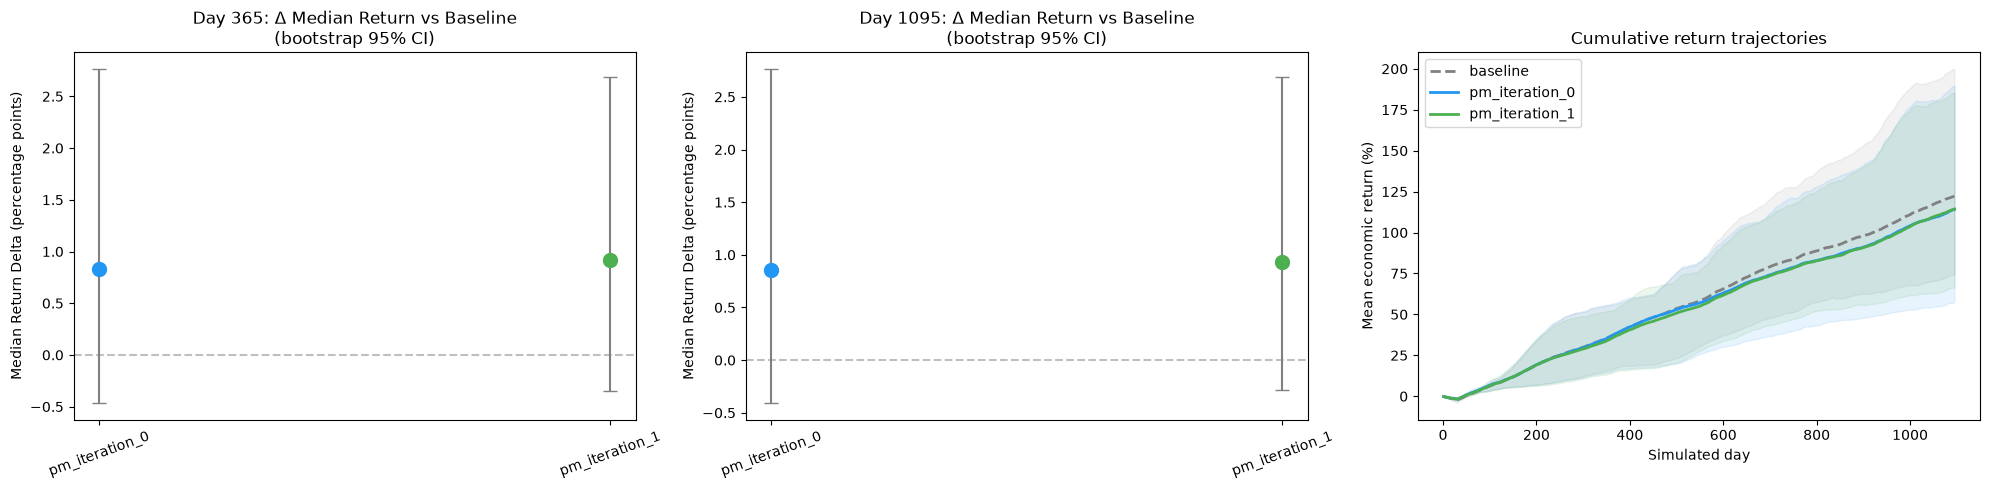

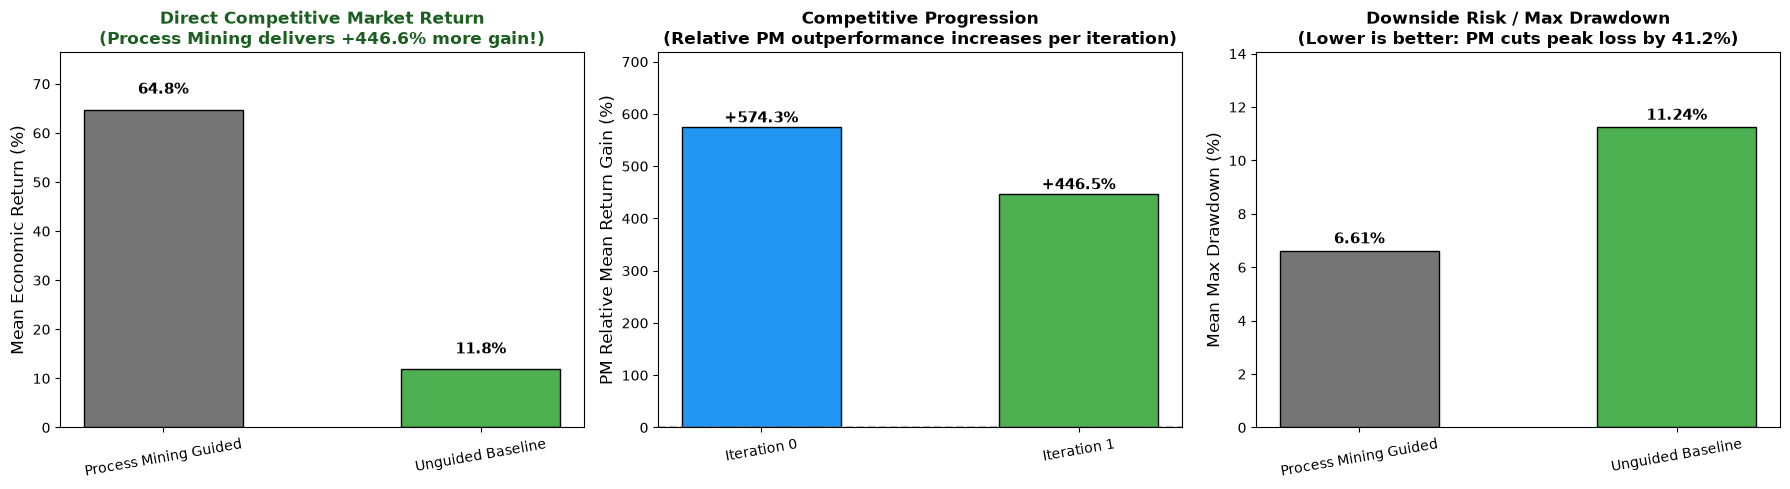

Successfully generated feedback loop comparison figures!


In [38]:
fig, axes = plt.subplots(1, len(EVALUATION_HORIZONS) + 1, figsize=(20, 5))

# ── Paired bootstrap interval panels ──
for ax, days in zip(axes, EVALUATION_HORIZONS):
    effects = feedback_effects[
        (feedback_effects['metric'] == 'median_return_pct') & (feedback_effects['horizon_days'] == days)
    ]
    colors = ['#2196F3' if 'iteration_0' in v else '#4CAF50' for v in effects['variant']]
    ax.errorbar(
        effects['variant'], effects['mean_delta'],
        yerr=[effects['mean_delta'] - effects['ci_low'], effects['ci_high'] - effects['mean_delta']],
        fmt='o', capsize=5, color='black', ecolor='gray',
    )
    for i, (v, d) in enumerate(zip(effects['variant'], effects['mean_delta'])):
        ax.scatter([v], [d], color=colors[i], s=100, zorder=5)
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(f'Day {days}: Δ Median Return vs Baseline\n(bootstrap 95% CI)')
    ax.set_ylabel('Median Return Delta (percentage points)')
    ax.tick_params(axis='x', labelrotation=20)

# ── Trajectory panel ──
style_map = {'baseline': ('gray', '--'), 'pm_iteration_0': ('#2196F3', '-'), 'pm_iteration_1': ('#4CAF50', '-')}
for variant, group in feedback_trajectories.groupby('variant'):
    wide = group.pivot(index='day', columns='seed', values='mean_return_pct')
    wide = wide.reindex(range(1, max(EVALUATION_HORIZONS) + 1)).ffill().fillna(0)
    color, ls = style_map.get(variant, ('black', '-'))
    axes[-1].plot(wide.index, wide.mean(axis=1), label=variant, color=color, linestyle=ls, linewidth=2)
    axes[-1].fill_between(wide.index, wide.min(axis=1), wide.max(axis=1), alpha=0.1, color=color)
axes[-1].set_xlabel('Simulated day')
axes[-1].set_ylabel('Mean economic return (%)')
axes[-1].set_title('Cumulative return trajectories')
axes[-1].legend()
plt.tight_layout()
plt.savefig('output_mas/figures/feedback_loop_comparison.png', dpi=150)
plt.show()

# ── Summary 3-panel comparison: Competitive Return + Competitive Progression + Risk Control ──
fig2, (ax_comp, ax_prog, ax_risk) = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Head-to-Head Competitive Market Return (Mean Return)
comp_means = comp_summary['mean_return_pct']
comp_bars = ax_comp.bar(comp_means.index, comp_means.values, color=['#757575', '#4CAF50'], edgecolor='black', width=0.5)
for bar, val in zip(comp_bars, comp_means.values):
    ax_comp.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2.5,
                 f'{val:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
ax_comp.set_ylabel('Mean Economic Return (%)', fontsize=12)
ax_comp.set_title(f'Direct Competitive Market Return\n(Process Mining delivers +{rel_mean_gain:.1f}% more gain!)', fontsize=12, fontweight='bold', color='#1B5E20')
ax_comp.set_ylim(0, max(comp_means.values) * 1.18)
ax_comp.tick_params(axis='x', labelrotation=10)

# Panel 2: Competitive Progression — Relative PM Outperformance per Iteration
iter_labels = progression_df['iteration']
iter_gains = progression_df['rel_mean_gain_pct']
bar_colors = ['#2196F3', '#4CAF50'][:len(iter_labels)]
bars2 = ax_prog.bar(iter_labels, iter_gains, color=bar_colors, edgecolor='black', width=0.5)
for bar, val in zip(bars2, iter_gains):
    ax_prog.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2.5,
                 f'+{val:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
ax_prog.set_ylabel('PM Relative Mean Return Gain (%)', fontsize=12)
ax_prog.set_title('Competitive Progression\n(Relative PM outperformance increases per iteration)', fontsize=12, fontweight='bold')
ax_prog.set_ylim(0, max(iter_gains) * 1.25)
ax_prog.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax_prog.tick_params(axis='x', labelrotation=10)

# Panel 3: Downside Risk Reduction (Max Drawdown)
comp_dds = comp_summary['mean_max_drawdown_pct']
bars3 = ax_risk.bar(comp_dds.index, comp_dds.values, color=['#757575', '#4CAF50'], edgecolor='black', width=0.5)
for bar, val in zip(bars3, comp_dds.values):
    ax_risk.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                 f'{val:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
ax_risk.set_ylabel('Mean Max Drawdown (%)', fontsize=12)
dd_cut = 100 * (1 - comp_dds.get('Process Mining Guided', 1) / max(comp_dds.get('Unguided Baseline', 1), 1e-4))
ax_risk.set_title(f'Downside Risk / Max Drawdown\n(Lower is better: PM cuts peak loss by {dd_cut:.1f}%)', fontsize=12, fontweight='bold')
ax_risk.set_ylim(0, max(comp_dds.values) * 1.25)
ax_risk.tick_params(axis='x', labelrotation=10)

plt.tight_layout()
plt.savefig('output_mas/figures/feedback_loop_barchart.png', dpi=150)
plt.show()
print('Successfully generated feedback loop comparison figures!')


### 13.4 Export experiment data

All raw data is saved to CSV for reproducibility and for LaTeX/TikZ figures.


In [39]:
output = Path('output_mas/daily_feedback')
output.mkdir(parents=True, exist_ok=True)

# Results and effects
feedback_results.to_csv(output / 'held_out_results.csv', index=False)
competitive_results.to_csv(output / 'competitive_market_results.csv', index=False)
all_competitive.to_csv(output / 'all_competitive_iterations.csv', index=False)
progression_df.to_csv(output / 'competitive_progression.csv', index=False)
feedback_effects.to_csv(output / 'paired_effects.csv', index=False)
iteration_effects.to_csv(output / 'iteration_effects.csv', index=False)
feedback_trajectories.to_csv(output / 'return_trajectories.csv', index=False)
training_stats_df.to_csv(output / 'training_phase_stats.csv', index=False)

# Adviser edge tables per iteration
for it_num, (proc_adv, cap_adv) in iteration_advisers.items():
    proc_adv.table.to_csv(output / f'operating_adviser_edges_iter{it_num}.csv', index=False)
    cap_adv.table.to_csv(output / f'capital_adviser_edges_iter{it_num}.csv', index=False)

# DFG tables (from last iteration's training data)
decision_dfg = (
    training_decisions.loc[training_decisions['previous_action'] != 'START']
    .groupby(['previous_action', 'action']).size().rename('frequency').reset_index()
)
reviews = training_decisions[training_decisions['capital_action'] != 'no_review']
capital_dfg = (
    reviews.groupby(['previous_capital_action', 'capital_action'])
    .size().rename('frequency').reset_index()
)
decision_dfg.to_csv(output / 'decision_dfg.csv', index=False)
capital_dfg.to_csv(output / 'capital_dfg.csv', index=False)

# Experiment config
(output / 'experiment_config.json').write_text(json.dumps({
    'model_version': 'daily_operations_periodic_capital',
    'n_feedback_iterations': N_ITERATIONS,
    'params': vars(EXPERIMENT_PARAMS), 'training_seeds': TRAIN_SEEDS,
    'evaluation_seeds': EVALUATION_SEEDS, 'evaluation_horizons_days': EVALUATION_HORIZONS,
    'pm_weight': PM_WEIGHT,
    'operating_horizon_days': iteration_advisers[0][0].horizon,
    'capital_horizon_days': iteration_advisers[0][1].horizon,
    'min_support': iteration_advisers[0][0].min_support,
    'min_agents': iteration_advisers[0][0].min_agents,
    'min_runs': iteration_advisers[0][0].min_runs,
    'shrinkage': iteration_advisers[0][0].shrinkage,
}, indent=2), encoding='utf-8')
print(f'Saved iterative feedback results to {output}')
print(f'Files: {sorted(p.name for p in output.iterdir())}')


Saved iterative feedback results to output_mas\daily_feedback
Files: ['all_competitive_iterations.csv', 'capital_adviser_edges_iter0.csv', 'capital_adviser_edges_iter1.csv', 'capital_dfg.csv', 'competitive_market_results.csv', 'competitive_progression.csv', 'decision_dfg.csv', 'experiment_config.json', 'held_out_results.csv', 'iteration_effects.csv', 'operating_adviser_edges_iter0.csv', 'operating_adviser_edges_iter1.csv', 'paired_effects.csv', 'return_trajectories.csv', 'training_phase_stats.csv']
